# Data analysis

In this notebook we study what the hourly Bitcoin data says **before any model is trained**: statistics of the returns, dependence over time, calendar patterns, market regimes, other markets (Binance, ETH) and macroeconomic variables.

The notebook brings together the analysis parts of the archived notebooks (`old_notebooks/`) and runs them on the base data, `data/btc_hourly.csv.gz`, produced by `hourly-base-data.ipynb`. The base data starts on 1 Jan 2018; **this notebook uses it from 1 Jan 2020** (`DATA_START` in section 1): 59,331 consecutive hours, 1 Jan 2020 → 8 Oct 2026. Nothing here reads the old `.npz` windows or the 1-minute Kaggle file.

**Two rules**

- Analyses that can steer a model choice (dependence tests, the AR model, regimes and clusters) use only the **train block (2020 → 2022)** and check themselves out of sample on the **validation block (Jan 2023 → Jun 2024)**. The **test block (Jul 2024 → Oct 2026)** is never used for them. These are the version 2/3 blocks, the split proposed in task 1 of the README.
- Descriptive sections (overview, distribution, drift of the calendar profile, other markets, macro correlation) use the whole series, test block included. Do not use them to choose hyperparameters.

**About the "What we see" texts and the conclusions.** They describe the outputs of this run (data from 1 Jan 2020 to 8 Oct 2026, frozen macro data of 20 Oct 2026; last run 21 Oct 2026). Where a result comes from another notebook (the model notebooks, an archived notebook or the correlation brief), the source is named. If the notebook is rerun on new data, re-check the numbers.

**Structure**

1. Settings and data.
2. Overview: price, volume and years.
3. Distribution of the returns.
4. Is there anything to predict? Autocorrelation and statistical tests.
5. Calendar patterns, and how they drift.
6. Volatility clustering and market regimes (daily).
7. Other markets: Binance and ETH.
8. Macroeconomic variables.
9. Conclusions.

## 1. Settings and data

Run the notebook from the repo root, so `data/` and `utils/` are found. The helpers come from `utils/` (see the README): statistical tests from `utils/hourly.py`, the daily/weekly/monthly frames from `utils/btc_data.py`, Binance from `utils/binance.py`, and the macro panels and correlation tools from `utils/macro.py` and `utils/correlation.py`.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sys.path.insert(0, os.getcwd())   # utils/ is in the repo root
from utils import hourly as U
from utils.btc_data import frames_from_hourly, return_summary, plot_return_hists
from utils.binance import load_binance
from utils.macro import load_macro, build_panels, level_panel
from utils.correlation import (TARGETS, prune_panels, corr_summary, resolve_focus,
                               lead_lag, corr_by_year, heatmap, rolling_corr_plot, cluster_order,
                               size_summary, weekday_rank_corr)

DATA_PATH = os.path.join("data", "btc_hourly.csv.gz")
DATA_START = pd.Timestamp("2020-01-01")         # first hour used in this notebook (the base data starts in 2018)
TRAIN_END = pd.Timestamp("2022-12-31 23:00")   # train block: 2020 -> 2022
VAL_END = pd.Timestamp("2024-06-30 23:00")     # validation block: Jan 2023 -> Jun 2024; test: Jul 2024 ->
ETF_DATE = pd.Timestamp("2024-01-11")          # first trading day of the US spot Bitcoin ETFs
RANDOM_STATE = 42

# Macro correlation (section 8)
START = str(DATA_START.date())   # same start as the BTC data above
METHOD = "spearman"         # correlation method (spearman is robust to fat tails)
PRUNE_THRESHOLD = 0.80      # max |r| allowed between two macro variables
TOP = 12                    # rows shown in each correlation table
FOCUS = ["SP500", "DXY", "US10Y", "Gold", "VIX", "HY_OAS", "NetLiquidity"]  # a-priori shortlist
MAX_LAG = {"D": 4, "W": 8}  # lead-lag range, in periods of each frequency
ROLL_WINDOW = 180           # rolling-correlation window, in daily observations
MACRO_FILE = os.path.join("data", "macro_raw.csv.gz")        # frozen copy of the FRED / Yahoo downloads
REFRESH_MACRO = False       # True = download again and overwrite the frozen copy
RELEASES_FILE = os.path.join("data", "release_dates.csv")   # US CPI, payrolls and FOMC releases (8.7)

# Colours and axes style shared by the plots
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#b4b2a9", "#52514e"


def tidy(ax, title=None):
    if title:
        ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

`Return` is converted to **percent** (0.4 = +0.4%), the unit used by `utils/hourly.py` and by the model notebooks. The grid check repeats the one of `hourly-base-data.ipynb`: the file must still be one continuous hourly series.

In [2]:
hourly = pd.read_csv(DATA_PATH, index_col="Timestamp", parse_dates=True)
hourly = hourly.loc[DATA_START:]                     # analysis period: 2020 ->
hourly["Return"] *= U.PCT
assert (hourly.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "the hourly grid has holes"

r = hourly["Return"]
ONE_HOUR = pd.Timedelta(hours=1)
r_tr = r.loc[:TRAIN_END]
r_va = r.loc[TRAIN_END + ONE_HOUR:VAL_END]
r_te = r.loc[VAL_END + ONE_HOUR:]

print(f"{len(hourly):,} hours   {hourly.index[0]} -> {hourly.index[-1]}")
for name, s in [("train", r_tr), ("val", r_va), ("test", r_te)]:
    print(f"  {name:<5} {len(s):>6,} hours  {s.index[0]} -> {s.index[-1]}   average |hourly move| {s.abs().mean():.3f}%")
print(f"no_trade hours: {hourly['no_trade'].sum()}, hours with at least one filled minute: {(hourly['filled_minutes'] > 0).mean():.1%}")

59,331 hours   2020-01-01 00:00:00 -> 2026-10-08 02:00:00
  train 26,304 hours  2020-01-01 00:00:00 -> 2022-12-31 23:00:00   average |hourly move| 0.496%
  val   13,128 hours  2023-01-01 00:00:00 -> 2024-06-30 23:00:00   average |hourly move| 0.300%
  test  19,899 hours  2024-07-01 00:00:00 -> 2026-10-08 02:00:00   average |hourly move| 0.319%
no_trade hours: 10, hours with at least one filled minute: 35.2%


The 10 `no_trade` hours (exchange outages) carry a made-up 0% return, and the hour after each outage carries the whole move. They are kept: they are 0.01% of the hours, too few to change the statistics below, and removing them would break the hourly grid that the autocorrelations rely on.

## 2. Overview: price, volume and years

The price on a log scale (equal vertical distances are equal percentage moves) with the traded volume below it. The dashed lines mark the start of the validation and test blocks.

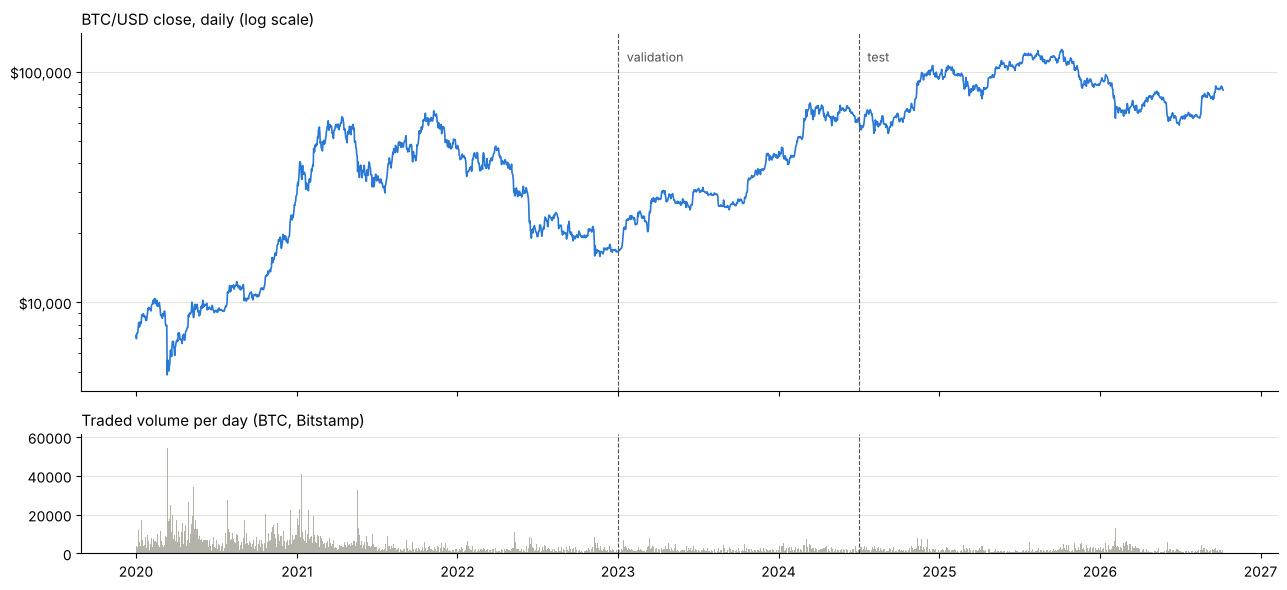

In [3]:
daily = hourly.resample("D").agg({"Close": "last", "Volume": "sum"})

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax[0].plot(daily.index, daily["Close"], color=BLUE, lw=1.2)
ax[0].set_yscale("log")
ax[0].yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("${x:,.0f}"))
ax[1].bar(daily.index, daily["Volume"], width=1.0, color=GREY)
for a in ax:
    for t in (TRAIN_END, VAL_END):
        a.axvline(t + ONE_HOUR, color=INK, lw=0.8, ls="--")
for t, label in [(TRAIN_END, "validation"), (VAL_END, "test")]:
    ax[0].text(t + pd.Timedelta(days=20), daily["Close"].max(), label, color=INK, fontsize=9, va="top")
tidy(ax[0], "BTC/USD close, daily (log scale)")
tidy(ax[1], "Traded volume per day (BTC, Bitstamp)")
plt.tight_layout()
plt.show()

**The years.** One row per calendar year: the average size of an hourly move, its standard deviation and excess kurtosis (fat tails), the share of up hours and up days, the price change over the year, and the outage hours. Daily returns are compounded from the hourly ones and only complete days are counted.

In [4]:
years = r.index.year
hours_per_day = r.resample("D").count()
d_ret = ((1 + r / U.PCT).resample("D").prod() - 1)[hours_per_day == 24] * U.PCT

yearly = pd.DataFrame({
    "hours": r.groupby(years).size(),
    "mean_abs_return_%": r.abs().groupby(years).mean(),
    "std_%": r.groupby(years).std(),
    "excess_kurtosis": r.groupby(years).apply(lambda s: s.kurt()),
    "up_hours": (r > 0).groupby(years).mean(),
    "up_days": (d_ret > 0).groupby(d_ret.index.year).mean(),
    "price_change_%": ((1 + r / U.PCT).groupby(years).prod() - 1) * U.PCT,
    "no_trade_hours": hourly["no_trade"].groupby(years).sum(),
})
yearly.index.name = "year"
yearly.round(3)

,hours,mean_abs_return_%,std_%,excess_kurtosis,up_hours,up_days,price_change_%,no_trade_hours
year,,,,,,,,
2020,8784,0.436,0.820,127.944,0.515,0.579,304.455,4
2021,8760,0.623,0.935,13.875,0.507,0.510,59.400,0
2022,8760,0.430,0.686,11.802,0.497,0.463,-64.236,2
2023,8760,0.269,0.454,25.781,0.511,0.496,155.675,1
2024,8784,0.370,0.564,7.467,0.512,0.525,120.978,2
2025,8760,0.307,0.476,12.408,0.503,0.501,-6.302,1
2026,6723,0.297,0.459,10.059,0.496,0.486,-5.005,0


**The price level is not stationary.** Prices from the later years lie far outside the range of the train block. The cell measures how much of the validation and test hours trade above the highest train price.

In [5]:
close = hourly["Close"]
train_max = close.loc[:TRAIN_END].max()
print(f"Close in the train block: {close.loc[:TRAIN_END].min():,.0f} to {train_max:,.0f} USD")
for name, s in [("validation", close.loc[TRAIN_END + ONE_HOUR:VAL_END]), ("test", close.loc[VAL_END + ONE_HOUR:])]:
    print(f"  {name:<10}: {s.min():,.0f} to {s.max():,.0f} USD, above the train maximum {(s > train_max).mean():.1%} of the hours")

Close in the train block: 4,112 to 68,627 USD
  validation: 16,504 to 73,608 USD, above the train maximum 6.0% of the hours
  test      : 49,814 to 126,111 USD, above the train maximum 72.1% of the hours


**What we see** *(this run, from 2020)*

- **Price.** Bitcoin starts 2020 below 10,000 USD, falls to the train low of 4,112 USD in the COVID crash of March 2020, rises 304% over 2020 and 59% over 2021 to the train high of 68,627 USD, and falls 64% in 2022. It rises again in 2023 (+156%) and 2024 (+121%) to new highs, peaking at 126,111 USD in the test block; 2025 (−6.3%) and 2026 up to 8 Oct (−5.0%) end slightly down.
- **The three blocks are different markets.** Train (2020–2022) contains the COVID crash, one large bull cycle and the 2022 bear market. Validation (Jan 2023 → Jun 2024) is mostly a recovery and a bull market. Test (Jul 2024 → Oct 2026) is a high-price period with a peak and a correction.
- **Volatility falls over time.** The average hourly move is 0.496% in train, 0.300% in validation and 0.319% in test; by year it goes from 0.62% (2021) to 0.27% (2023). Raw errors are therefore not comparable between blocks, so errors are reported relative to a baseline ("skill").
- **The price level is not stationary.** 6.0% of the validation hours and **72.1% of the test hours** trade above the highest train price. Tree models cannot predict outside the range they were trained on, and linear models would extrapolate the level in a meaningless way, so the models use *scale-free* features (returns, ratios, volatilities).
- **Volume in BTC is not comparable across years.** Bitstamp's daily volume reached 20,000–55,000 BTC on the busiest days of 2020 and early 2021, and stays mostly below 10,000 BTC from mid-2021 (one BTC is worth much more, and trading spread over other exchanges). Only relative volume (last day vs last week) is used as a feature.
- **Up hours are 49.6–51.5% of every year**, also in years with −64% or +304%. The direction of a single hour says almost nothing about the year.
- **Fat tails in every year:** the hourly excess kurtosis is between 7.5 (2024) and 26 (2023), and 128 in 2020 (COVID crash). There are at most 4 `no_trade` hours in a year.

## 3. Distribution of the returns

Log returns at four timeframes: hourly, daily, weekly and monthly. The daily, weekly and monthly candles are built from the base series with `frames_from_hourly` (incomplete periods at the end are dropped). For a normal distribution the excess kurtosis would be 0.

,start,n,mean,std,skew,excess_kurtosis,min,max
H,2020-01-01,59330,0.004135,0.658325,-0.360776,54.908628,-18.090334,20.548271
D,2020-01-01,2471,0.099192,3.210587,-1.46615,25.550457,-49.396946,17.772991
W,2020-01-05,352,0.700185,8.01831,-0.561515,2.955981,-40.773813,23.480499
ME,2020-01-31,80,2.740739,17.481738,-0.145296,0.264948,-46.632483,38.64189


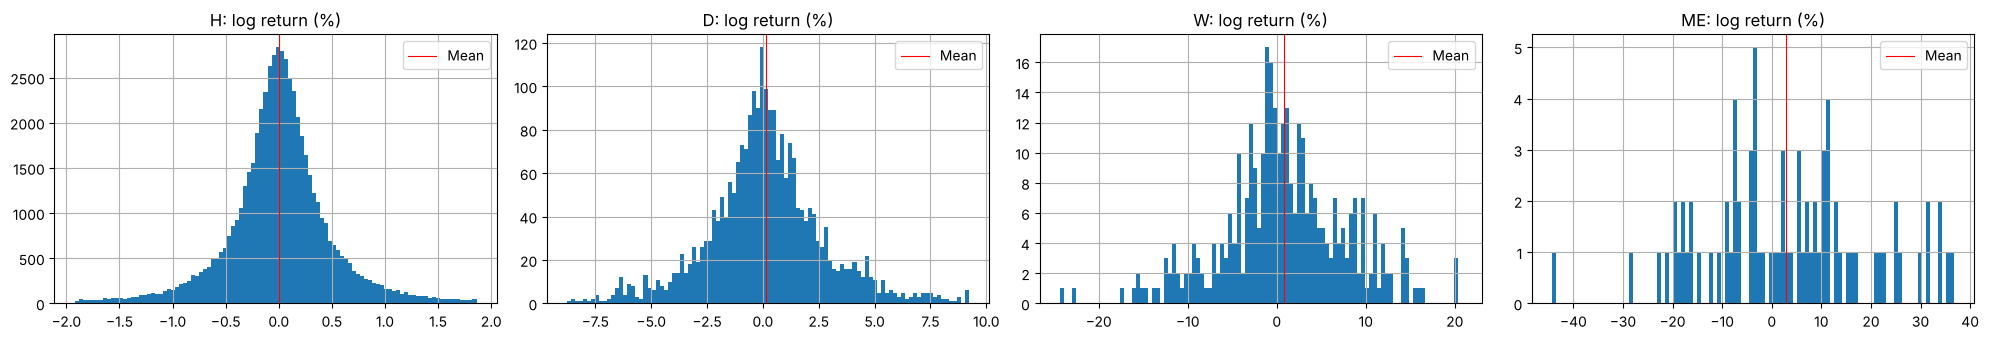

In [6]:
frames = {"H": hourly, **frames_from_hourly(hourly)}
display(return_summary(frames).round(3))
plot_return_hists(frames)
plt.show()

**Mean return per timeframe** *(from the first version of the correlation notebook, `old_notebooks/correlation_analyses.ipynb`)*. "For investigating possible correlations between the BTC price and other variables it is important to take into consideration the different timescales these changes may manifest themselves in." The table gives the mean change of each timeframe and its **daily equivalent** (the mean divided by the days in one period), so the timeframes can be compared. Changes are compounded from the hourly returns; the first and last periods are dropped because they may be incomplete.

In [7]:
TIMEFRAMES = {"hourly": ("h", 1 / 24), "12 hours": ("12h", 0.5), "daily": ("D", 1), "3 days": ("3D", 3),
              "weekly": ("W", 7), "2 weeks": ("2W", 14), "monthly": ("ME", 30), "3 months": ("3ME", 90)}
tf_rows = {}
for name, (rule, days_per_period) in TIMEFRAMES.items():
    pct = ((1 + r / U.PCT).resample(rule).prod() - 1) * U.PCT
    if rule != "h":
        pct = pct.iloc[1:-1]
    tf_rows[name] = {"periods": len(pct), "mean_%": pct.mean(), "daily_equivalent_%": pct.mean() / days_per_period,
                     "median_%": pct.median(), "std_%": pct.std(), "up_share": (pct > 0).mean()}
pd.DataFrame(tf_rows).T.round(3)

,periods,mean_%,daily_equivalent_%,median_%,std_%,up_share
hourly,59331.0,0.006,0.151,0.006,0.658,0.506
12 hours,4943.0,0.074,0.149,0.049,2.217,0.519
daily,2471.0,0.150,0.150,0.037,3.161,0.509
3 days,823.0,0.441,0.147,0.478,5.314,0.548
weekly,352.0,1.022,0.146,0.464,7.970,0.531
2 weeks,176.0,2.173,0.155,1.392,12.401,0.551
monthly,80.0,4.329,0.144,2.646,18.160,0.562
3 months,26.0,12.879,0.143,7.630,37.875,0.538


**What we see** *(this run)* The daily equivalent of the mean change is almost the same at every timeframe, **0.14–0.16% per day**. The mean is above the median at most timeframes (monthly 4.3% vs 2.6%; 3 months 12.9% vs 7.6%) and 51–56% of the periods are up: the average gain comes partly from a few very large up moves rather than from a steady drift. The archived notebook found 0.26–0.36% per day on data from 2012; the difference is the start date, since the early years contained Bitcoin's much faster growth.

**How fat are the tails?** The Jarque–Bera test checks whether skewness and kurtosis match a normal distribution. The table also compares the share of returns more than 3 and 5 standard deviations from the mean with what a normal distribution would give.

,n,Jarque-Bera,p-value,share |z| > 3,normal |z| > 3,share |z| > 5,normal |z| > 5
H,"59,330","7,453,229",0.0e+00,1.78%,0.27%,0.408%,0.00006%
D,"2,471","67,814",0.0e+00,1.42%,0.27%,0.121%,0.00006%
W,352,141,1.9e-31,1.42%,0.27%,0.284%,0.00006%
ME,80,0,8.3e-01,0.00%,0.27%,0.000%,0.00006%


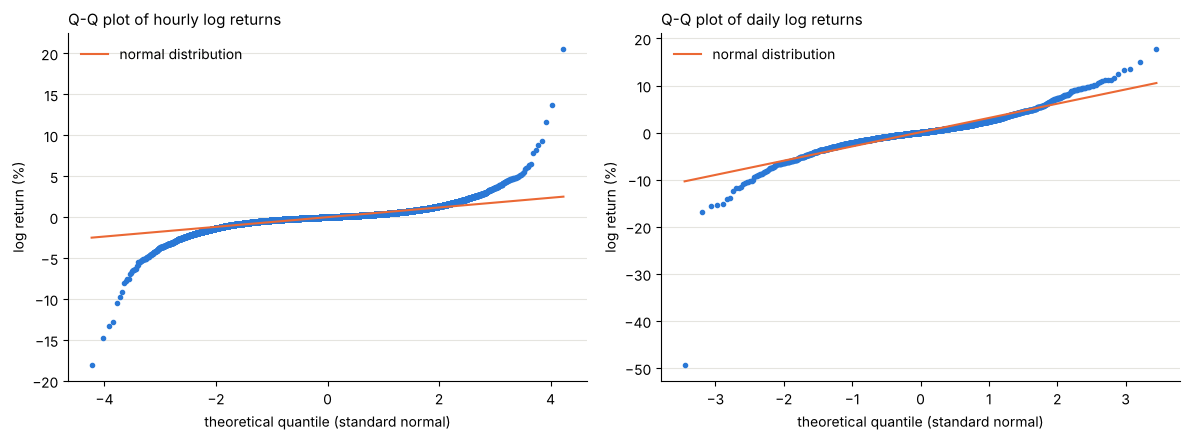

In [8]:
tail_rows = {}
for f, df in frames.items():
    lr = 100 * np.log(df["Close"]).diff().dropna()
    z = (lr - lr.mean()) / lr.std()
    jb = stats.jarque_bera(lr)
    tail_rows[f] = {"n": len(lr), "Jarque-Bera": jb.statistic, "p-value": jb.pvalue,
                    "share |z| > 3": (z.abs() > 3).mean(), "normal |z| > 3": 2 * stats.norm.sf(3),
                    "share |z| > 5": (z.abs() > 5).mean(), "normal |z| > 5": 2 * stats.norm.sf(5)}
display(pd.DataFrame(tail_rows).T.style.format(
    {"n": "{:,.0f}", "Jarque-Bera": "{:,.0f}", "p-value": "{:.1e}", "share |z| > 3": "{:.2%}",
     "normal |z| > 3": "{:.2%}", "share |z| > 5": "{:.3%}", "normal |z| > 5": "{:.5%}"}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, f, name in [(ax[0], "H", "hourly"), (ax[1], "D", "daily")]:
    lr = 100 * np.log(frames[f]["Close"]).diff().dropna()
    (osm, osr), (slope, intercept, _) = stats.probplot(lr, dist="norm")
    a.plot(osm, osr, "o", ms=3, color=BLUE)
    a.plot(osm, slope * osm + intercept, color=ORANGE, lw=1.5, label="normal distribution")
    a.set_xlabel("theoretical quantile (standard normal)")
    a.set_ylabel("log return (%)")
    a.legend(frameon=False)
    tidy(a, f"Q-Q plot of {name} log returns")
plt.tight_layout()
plt.show()

**The largest hourly moves.** If an outage or a data error were driving the tails, it would show up here.

In [9]:
largest = r.abs().nlargest(15).index
hourly.loc[largest, ["Open", "Close", "Volume", "Return", "filled_minutes"]].sort_index()

,Open,Close,Volume,Return,filled_minutes
Timestamp,,,,,
2020-03-12 10:00:00,7342.49,6334.44,6856.299515,-13.728994,0
2020-03-12 23:00:00,5798.25,4841.67,8051.447101,-16.548398,0
2020-03-13 01:00:00,4671.14,4111.78,2209.176426,-11.979141,0
2020-03-13 02:00:00,4115.92,5049.75,5532.585803,22.811775,0
2020-03-13 04:00:00,5362.37,4865.87,2396.046872,-9.310548,0
2020-03-13 09:00:00,5355.00,5842.71,1692.264061,9.209533,0
2020-03-13 19:00:00,5013.93,5453.51,2467.995491,8.531666,0
2020-03-15 21:00:00,5180.00,5942.09,3288.327897,14.734976,0
2020-03-15 22:00:00,5942.04,5353.65,2785.368376,-9.902913,0


**What we see** *(this run)*

- **Very fat tails at short horizons.** Excess kurtosis is 54.9 for hourly, 25.6 for daily, 3.0 for weekly and 0.3 for monthly log returns. 1.78% of the hourly returns are more than 3 standard deviations from the mean (a normal distribution gives 0.27%, about 7× less) and 0.41% are beyond 5 standard deviations: about 1 hour in 245, where a normal distribution would give about 1 in 1.7 million. The Q-Q plots bend away from the line at both ends.
- **Aggregating makes returns more normal.** Jarque–Bera rejects normality for hourly, daily and weekly returns (weekly p = 1.9×10⁻³¹), but not for monthly ones (p = 0.83, no month beyond 3 standard deviations). With only 80 months, this test has little power.
- **Daily returns are skewed to the left** (skewness −1.47): the largest falls are larger than the largest rises. The worst day is −49% in log terms (−39%), in the COVID crash of March 2020; the best is +18%.
- **The largest hourly moves are real events, not data errors.** The 15 largest moves are between 7.7% and 22.8% in absolute value, and 7 hours move more than 10%. **10 of the 15 are in the COVID crash of 12–23 March 2020**, including −16.5% at 23:00 on 12 March and the largest move of all, +22.8% at 02:00 on 13 March, one hour after −12.0%. The others: 10 May 2020 (−8.7%, the eve of the Bitcoin halving), Musk adding #bitcoin to his Twitter profile (29 Jan 2021, +12.3%), Tesla's Bitcoin purchase (8 Feb 2021, +9.8%) and the crashes of 19 and 21 May 2021 (−12.4% and −7.7%). All have high volume and no filled minutes. None is after May 2021, in line with the calmer later years.
- **Consequence.** The data is clean; the noise is the market itself, so it cannot be "cleaned away". It is handled with rank (Spearman) correlations in section 8, robust losses (Huber) and volatility scaling in the models, and aggregated targets. For the RNN/LSTM, "the MSE loss is dominated by the few extreme hours" (`model_test.ipynb`).

## 4. Is there anything to predict?

*Section and texts from `bitcoin-models-v3.ipynb` (A1). Train block only.*

**Autocorrelation** (ACF) at lag *k* is the correlation between the value of an hour and the value *k* hours earlier. If returns were predictable from their own past, some autocorrelations would be clearly different from 0. Three series are examined:

- the **returns** *r* (direction and size together),
- the **absolute returns** |*r*| (only the size of the move),
- the **squared returns** *r*² (size, with more weight on big moves).

The dashed lines show ±1.96/√n: values outside them are significant at 5% if the true correlation were 0.

The **Ljung–Box test** checks whether the first 24 autocorrelations are *jointly* zero. A tiny p-value means "there is some dependence".

A significant correlation is not the same as a useful one. The share of variance that a *linear* model of the last 24 returns can explain is checked directly by fitting an AR(24) model (a linear regression on the last 24 returns) on the train block and testing it on the validation block.

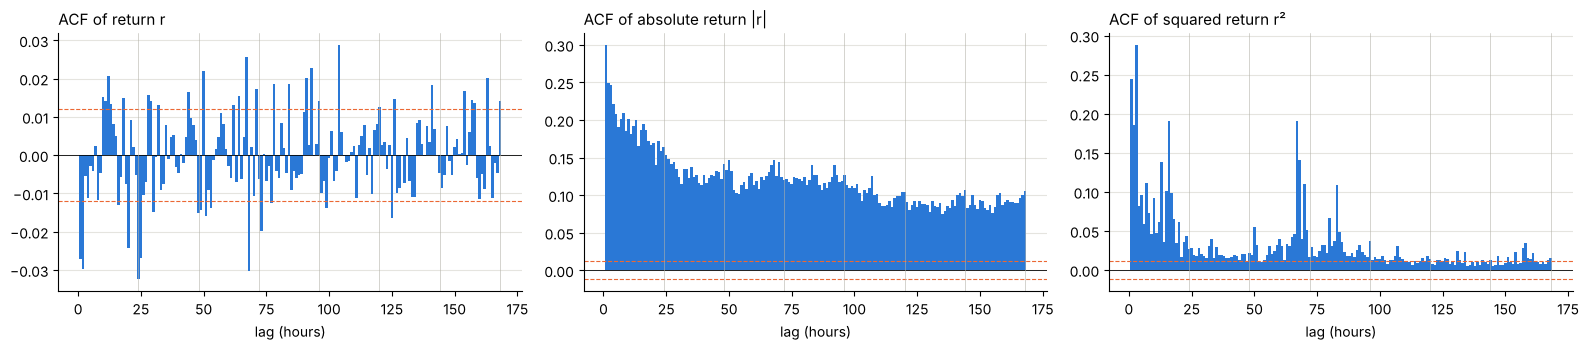

,Q (24 lags),p-value,ACF lag 1,ACF lag 24,sum of ACF² lags 1-24
return r,140.4983,0.0,-0.0270,-0.0324,0.0053
|r|,24537.3876,0.0,0.2999,0.1637,0.9324
r²,8437.2825,0.0,0.2439,0.0271,0.3207


n = 26,304 hours, significance band ±0.0121


In [10]:
LAGS = 168


def acf(x, lags):
    x = np.asarray(x, float) - np.mean(x)
    den = (x ** 2).sum()
    return np.array([(x[k:] * x[:-k]).sum() / den for k in range(1, lags + 1)])


acfs = {"return r": acf(r_tr, LAGS), "absolute return |r|": acf(r_tr.abs(), LAGS), "squared return r²": acf(r_tr ** 2, LAGS)}
band = 1.96 / np.sqrt(len(r_tr))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
for a, (name, v) in zip(ax, acfs.items()):
    a.bar(range(1, LAGS + 1), v, width=1.0, color=BLUE)
    a.axhline(band, ls="--", c=ORANGE, lw=0.8)
    a.axhline(-band, ls="--", c=ORANGE, lw=0.8)
    a.axhline(0, c="k", lw=0.6)
    for d in range(24, LAGS + 1, 24):
        a.axvline(d, c=GREY, lw=0.4)
    a.set_xlabel("lag (hours)")
    tidy(a, f"ACF of {name}")
plt.tight_layout()
plt.show()

lb = pd.DataFrame({name: dict(zip(["Q (24 lags)", "p-value"], U.ljung_box(x, 24)))
                   for name, x in [("return r", r_tr), ("|r|", r_tr.abs()), ("r²", r_tr ** 2)]}).T
lb["ACF lag 1"] = [v[0] for v in acfs.values()]
lb["ACF lag 24"] = [v[23] for v in acfs.values()]
lb["sum of ACF² lags 1-24"] = [(v[:24] ** 2).sum() for v in acfs.values()]
display(lb.round(4))
print(f"n = {len(r_tr):,} hours, significance band ±{band:.4f}")

In [11]:
# AR(24): linear regression of each hour's return on the 24 previous returns
def lag_matrix(x, k=24):
    x = np.asarray(x)
    return np.column_stack([x[k - j - 1: len(x) - j - 1] for j in range(k)]), x[k:]


Xa, ya = lag_matrix(r_tr)
Xv, yv = lag_matrix(r_va)
for name, target_tr, target_va in [("return r", ya, yv), ("absolute return |r|", np.abs(ya), np.abs(yv))]:
    Xa_, Xv_ = (Xa, Xv) if name == "return r" else (np.abs(Xa), np.abs(Xv))
    ar = Ridge(alpha=1e-6).fit(Xa_, target_tr)
    ins, oos = U.r2(target_tr, ar.predict(Xa_)), U.r2(target_va, ar.predict(Xv_))
    ins0, oos0 = U.r2_oos(target_tr, ar.predict(Xa_)), U.r2_oos(target_va, ar.predict(Xv_))
    print(f"AR(24) on {name:<20}: R² train {ins:+.4f}  validation {oos:+.4f}   "
          f"(R²_oos vs zero: train {ins0:+.4f}, validation {oos0:+.4f})")

AR(24) on return r            : R² train +0.0057  validation -0.0019   (R²_oos vs zero: train +0.0057, validation -0.0014)
AR(24) on absolute return |r| : R² train +0.1837  validation +0.1018   (R²_oos vs zero: train +0.4824, validation +0.4376)


**What we see** *(this run, train block 2020–2022)*

- **Returns (left plot).** Most autocorrelations are inside the significance band (±0.012). The clear exceptions are negative: lag 1 (−0.027), lag 2 (about −0.029) and lag 24 (−0.032, the largest), with a few more near −0.025 to −0.030 (around lags 22 and 68). These are small **reversals**: after a move, the next two hours and the same hour of the next day tend to move slightly the other way. The Ljung–Box test rejects "no dependence" (Q = 140, p ≈ 0), so the effect is real. But it is tiny: the sum of the squared autocorrelations over 24 lags is **0.0053**, so a linear model of the last 24 returns can explain at most ≈0.5% of the variance. The AR(24) model confirms it: R² +0.0057 on train and **−0.0019 on validation**, worse than predicting the mean.
- **Size of the move (middle plot).** The absolute returns are strongly autocorrelated: 0.30 at lag 1, 0.16 at lag 24 and still about 0.09–0.10 a full week later (*volatility clustering*, with a long memory). The small bumps every 24 lags are the daily rhythm of section 5. The AR(24) model on |r| explains **10.2% of the validation variance** one hour ahead (18.4% on train). The R²_oos column compares with a forecast of zero, which is not a sensible baseline for a size, so it is not used for |r|.
- **Squared returns (right plot).** Same message, but noisier: 0.24 at lag 1 but only 0.03 at lag 24. Squaring gives enormous weight to a few extreme hours, and the isolated spikes (e.g. around lag 67) come from a handful of crash hours. This is why |r| is used as the hourly volatility target.

**Is the reversal stable from year to year?** Version 3 called the reversal unstable; `v3-extensions.ipynb` later found that the lag-1 reversal still gives a small direction signal for the next hour. The table repeats the main numbers for each year of the train and validation blocks (the test block is left out).

In [12]:
r_tv = r.loc[:VAL_END]
acf_years = {}
for y, s in r_tv.groupby(r_tv.index.year):
    a_r, a_abs = acf(s, 24), acf(s.abs(), 24)
    acf_years[y] = {"ACF r lag 1": a_r[0], "ACF r lag 2": a_r[1], "ACF r lag 24": a_r[23],
                    "Ljung-Box p (r, 24 lags)": U.ljung_box(s, 24)[1],
                    "ACF |r| lag 1": a_abs[0], "ACF |r| lag 24": a_abs[23]}
display(pd.DataFrame(acf_years).T.round(4))

,ACF r lag 1,ACF r lag 2,ACF r lag 24,"Ljung-Box p (r, 24 lags)",ACF |r| lag 1,ACF |r| lag 24
2020,-0.0760,-0.0453,-0.0243,0.0000,0.3570,0.1453
2021,-0.0042,-0.0289,-0.0447,0.0000,0.2196,0.1328
2022,-0.0002,-0.0099,-0.0214,0.2496,0.2808,0.1772
2023,-0.0378,0.0285,-0.0225,0.0000,0.2413,0.0997
2024,0.0004,-0.0286,-0.0068,0.0176,0.2960,0.1334


**What we see** *(this run, train and validation years; 2024 is only January–June)*

- **The sign of the reversal is consistent, its size is not.** The lag-24 autocorrelation is negative in all 5 years (−0.007 to −0.045) and lag 2 in 4 of 5 (2023: +0.029). Lag 1 is clearly negative only in 2020 (−0.076, the COVID crash year) and 2023 (−0.038), and about zero in 2021, 2022 and 2024. Ljung–Box rejects "no dependence" in every year except 2022 (p = 0.25).
- **Volatility clustering is stable:** the |r| autocorrelation is 0.22–0.36 at lag 1 and 0.10–0.18 at lag 24 in every year.
- **Link to the models** *(README, test block)*: reversing the last hour gives AUC 0.528 for the next hour's direction, and the Gradient Boosting classifier 0.540, right 56.6% of the time on its 10% most confident calls. The table shows why this signal is small and why its strength changes from year to year.

## 5. Calendar patterns, and how they drift

*Section and texts from `bitcoin-models-v3.ipynb` (A1). Train block only.*

**Calendar patterns.** Does the time of day or the day of the week matter? The plots show the average return and the average *size* of the move for every hour of the day (UTC) and every weekday, with 95% confidence intervals (train block).

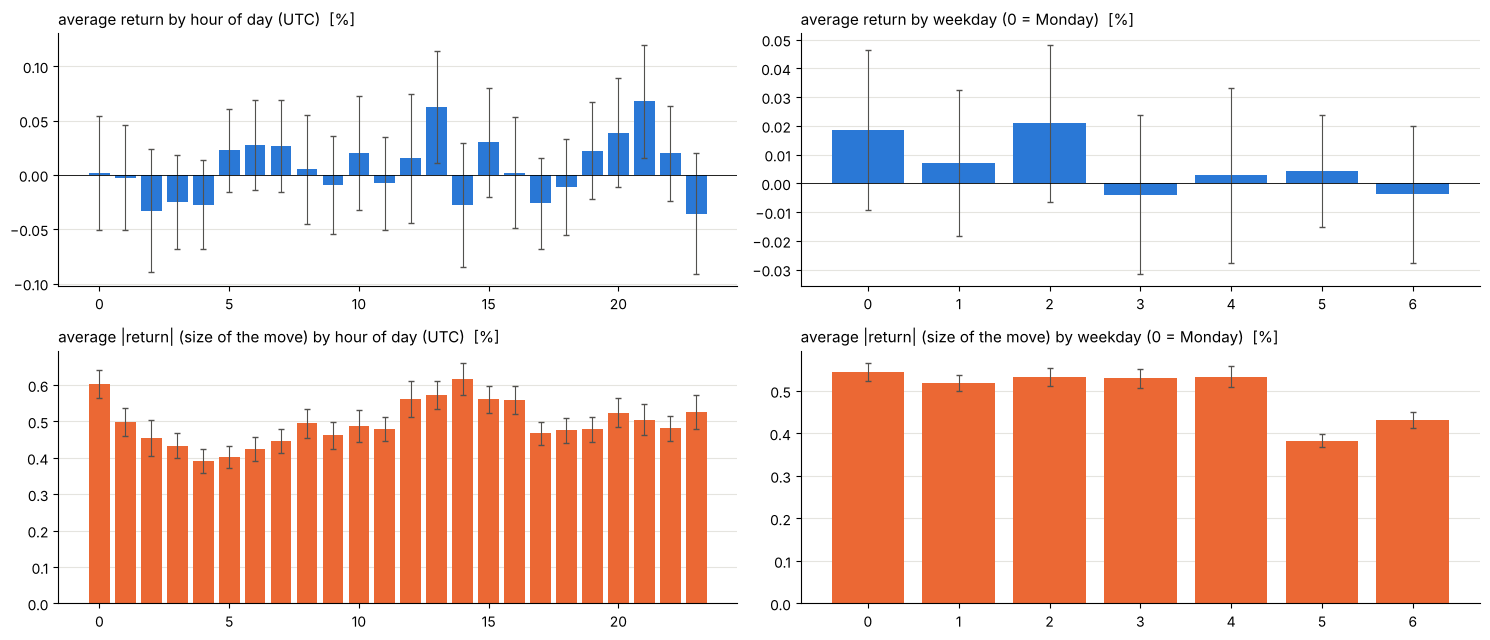

|r| by hour: lowest 0.392% at 4:00, highest 0.618% at 14:00 (ratio 1.58)
|r| weekend / weekdays: 0.77
ANOVA 'mean return equal for all 24 hours': p = 0.128  |  'mean |r| equal for all hours': p = 1.3e-32


In [13]:
cal = pd.DataFrame({"r": r_tr, "abs": r_tr.abs(), "hour": r_tr.index.hour, "dow": r_tr.index.dayofweek})
fig, ax = plt.subplots(2, 2, figsize=(15, 6.5))
for j, key in enumerate(["hour", "dow"]):
    g = cal.groupby(key)
    for i, col in enumerate(["r", "abs"]):
        m, se = g[col].mean(), g[col].std() / np.sqrt(g[col].count())
        ax[i, j].bar(m.index, m.values, yerr=1.96 * se.values, capsize=2, color=BLUE if col == "r" else ORANGE,
                     error_kw={"ecolor": INK, "lw": 0.8})
        ax[i, j].axhline(0, c="k", lw=0.6)
        tidy(ax[i, j], f"{'average return' if col == 'r' else 'average |return| (size of the move)'} by "
                       f"{'hour of day (UTC)' if key == 'hour' else 'weekday (0 = Monday)'}  [%]")
plt.tight_layout()
plt.show()

prof = cal.groupby("hour")["abs"].mean()
print(f"|r| by hour: lowest {prof.min():.3f}% at {prof.idxmin()}:00, highest {prof.max():.3f}% at {prof.idxmax()}:00 "
      f"(ratio {prof.max() / prof.min():.2f})")
wk = cal.groupby("dow")["abs"].mean()
print(f"|r| weekend / weekdays: {wk[5:].mean() / wk[:5].mean():.2f}")
t_hour = stats.f_oneway(*[g.values for _, g in cal.groupby("hour")["r"]])
t_hour_abs = stats.f_oneway(*[g.values for _, g in cal.groupby("hour")["abs"]])
print(f"ANOVA 'mean return equal for all 24 hours': p = {t_hour.pvalue:.3f}  |  "
      f"'mean |r| equal for all hours': p = {t_hour_abs.pvalue:.1e}")

**What we see in the calendar** *(this run, train block 2020–2022)*

- **Average return by hour:** every bar is within about ±0.07%, against an average hourly move of 0.496%. The ANOVA gives p = 0.13, so the hours are not different on average. Two hours have an interval that excludes 0 (13:00 and 21:00, both positive), but with 24 hours tested one or two such hours are expected by chance anyway. By weekday every interval crosses 0. The calendar gives no usable direction signal.
- **Size of the move by hour:** a very clear pattern (ANOVA p ≈ 10⁻³²). The busiest hour is now **14:00 UTC** (0.618%), with 00:00 UTC (the daily candle close, about 0.60%) close behind and the whole 12–16 UTC block above average. The quietest hours are 03–05 UTC (0.392% at 04:00), so the busiest hour moves **1.58×** as much as the quietest.
- **Size of the move by weekday:** Saturday (about 0.38%) and Sunday (about 0.43%) are much calmer than weekdays (0.52–0.55%): weekend hours move **0.77×** as much as weekday hours.

**Does the daily rhythm drift?** *(descriptive, whole series)* `v3-extensions.ipynb` reported that "the daily rhythm of volatility changed after 2024 (the 14 UTC peak grew from 1.2× to 1.7× the average hour, probably because of the US spot ETFs)". The original analysis (`hourly-move-size.ipynb`) was deleted, so it is rebuilt here: the size of the move in each hour divided by the average hour, per year, and before and after the first ETF trading day.

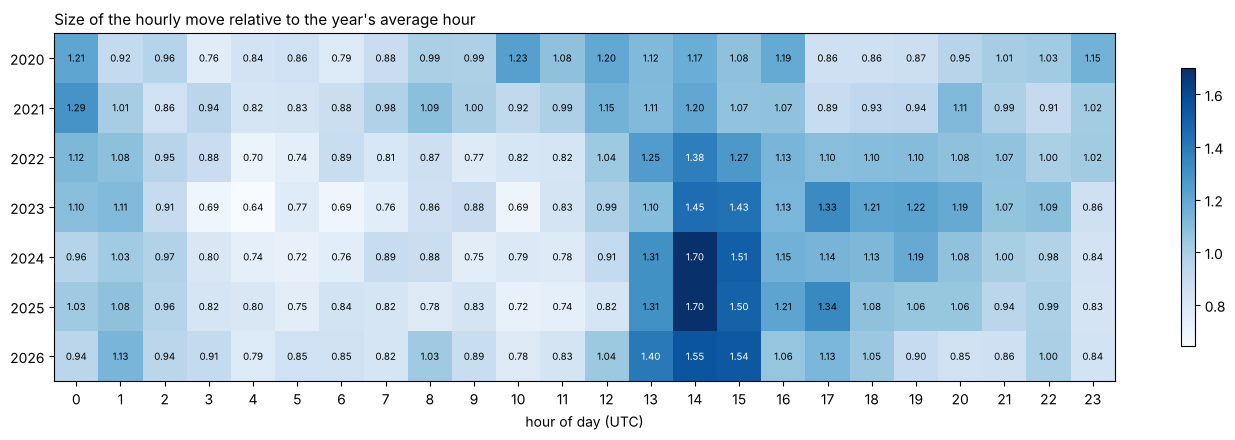

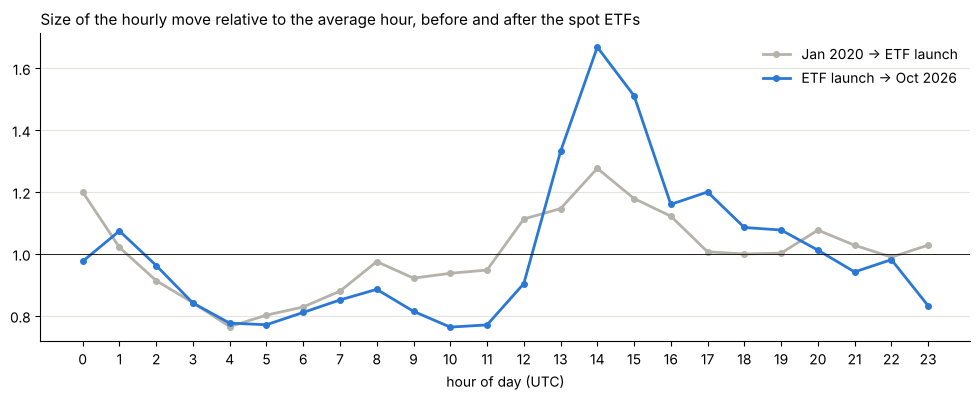

Timestamp,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Jan 2020 -> ETF launch,1.20,1.02,0.91,0.84,0.76,0.80,0.83,0.88,0.97,0.92,0.94,0.95,1.11,1.15,1.28,1.18,1.12,1.01,1.00,1.00,1.08,1.03,0.99,1.03
ETF launch -> Oct 2026,0.98,1.07,0.96,0.84,0.78,0.77,0.81,0.85,0.89,0.81,0.76,0.77,0.90,1.33,1.67,1.51,1.16,1.20,1.09,1.08,1.01,0.94,0.98,0.83


|r| weekend / weekdays by year: {2020: 0.8, 2021: 0.82, 2022: 0.66, 2023: 0.59, 2024: 0.57, 2025: 0.6, 2026: 0.58}


In [14]:
a = r.abs()
rel_hour = a.groupby([a.index.year, a.index.hour]).mean().unstack()
rel_hour = rel_hour.div(rel_hour.mean(axis=1), axis=0)          # 1 = the average hour of that year

fig, ax = plt.subplots(figsize=(14, 4.5))
im = ax.imshow(rel_hour.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(24))
ax.set_yticks(range(len(rel_hour)))
ax.set_yticklabels(rel_hour.index)
for i in range(rel_hour.shape[0]):
    for j in range(rel_hour.shape[1]):
        v = rel_hour.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 1.35 else "black")
ax.set_xlabel("hour of day (UTC)")
ax.set_title("Size of the hourly move relative to the year's average hour", loc="left", fontsize=11)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

periods = {f"{DATA_START:%b %Y} -> ETF launch": a.loc[:ETF_DATE - ONE_HOUR], "ETF launch -> Oct 2026": a.loc[ETF_DATE:]}
etf_prof = pd.DataFrame({k: s.groupby(s.index.hour).mean() / s.mean() for k, s in periods.items()})
fig, ax = plt.subplots(figsize=(12, 4))
for (k, col), c in zip(etf_prof.items(), [GREY, BLUE]):
    ax.plot(etf_prof.index, col, marker="o", ms=4, lw=2, color=c, label=k)
ax.axhline(1, c="k", lw=0.6)
ax.set_xticks(range(24))
ax.set_xlabel("hour of day (UTC)")
ax.legend(frameon=False)
tidy(ax, "Size of the hourly move relative to the average hour, before and after the spot ETFs")
plt.show()
display(etf_prof.T.round(2))

weekend = a.groupby([a.index.year, a.index.dayofweek >= 5]).mean().unstack()
print("|r| weekend / weekdays by year:", (weekend[True] / weekend[False]).round(2).to_dict())

**What we see** *(this run, whole series from 2020)*

- **The daily rhythm has changed.** Before the spot ETFs, 14 UTC was already the busiest hour (1.28× the average hour) together with 00 UTC (1.20×). Since the ETF launch, 14 UTC is **1.67×**, 15 UTC 1.51× and 13 UTC 1.33×, while 00 UTC drops to 0.98× and the hours 04–11 UTC drop to about 0.76–0.89×.
- **The change is gradual, not only the ETFs.** At 14 UTC: 1.17× (2020), 1.20× (2021), 1.38× (2022), 1.45× (2023), 1.70× (2024 and 2025), 1.55× (2026). The growth starts in 2022, two years before the ETFs, and jumps in 2024. The 00 UTC peak fades: 1.21–1.29× in 2020–2021, 0.94–1.03× since 2024. Both fit Bitcoin trading more like a US asset (13–15 UTC is the US stock-market session). The US data releases are not the reason: removing release days does not change the 14 UTC peak (section 8.7).
- **Weekends got much quieter.** Weekend hours moved 0.80–0.82× as much as weekday hours in 2020–2021, 0.66× in 2022 and 0.57–0.60× since 2023.
- **Consequence for the models.** A calendar profile learned on 2020–2022 underestimates 13–15 UTC and overestimates weekends and 00 UTC in the validation and test blocks. Recent data matters: in `classical-models.ipynb`, monthly refits with recency weights are the largest single gain (hourly move size R² 0.117 → 0.144 on test, README).

**Conclusion of sections 4–5: why does it look like noise?** The **direction** of the next hours is almost pure noise: the only dependence is a tiny reversal that explains well under 1% of the variance and changes in size from year to year. The **size** of the next hours is clearly predictable from recent volatility, the hour of the day and the weekday, but the daily rhythm itself drifts. The hourly return target asks the one question the data cannot answer.

## 6. Volatility clustering and market regimes (daily)

*Section and texts from `course-methods.ipynb`. One forecast per day, at 23:00, for the next 24 hours. Statistics, correlations and clusters are fitted on the train days; the validation days check them. (`course-methods.ipynb` used train 2018–2023 and test 2024+; here the common blocks are used.)*

**Attributes.** Each attribute describes the last day or the last week, and only uses hours up to the moment of the forecast:

| Attribute | Meaning |
|---|---|
| `ret_1d`, `ret_7d`, `ret_30d` | price change over the last 24 h, 7 days and 30 days (%) |
| `size_1d` | average size of the hourly changes over the last 24 h (mean \|change\|) |
| `vol_1d`, `vol_7d` | standard deviation of the hourly changes over the last 24 h / 7 days |
| `range_1d` | distance between the highest and the lowest price of the last 24 h (%) |
| `volume_ratio` | traded volume of the last 24 h compared with the weekly average (log) |
| `last_hour` | the change in the last hour |

**Targets.** `size_next`: average \|hourly change\| of the next 24 h. `ret_next`: change over the next 24 h. `up_next`: 1 if the price is higher after 24 h. `shift(-24)` takes values from the future, so these columns are only used as answers, never as inputs.

In [15]:
volume = hourly["Volume"].clip(lower=0)
attributes = pd.DataFrame({
    "ret_1d": (close / close.shift(24) - 1) * 100,
    "ret_7d": (close / close.shift(168) - 1) * 100,
    "ret_30d": (close / close.shift(720) - 1) * 100,
    "size_1d": r.abs().rolling(24).mean(),
    "vol_1d": r.rolling(24).std(),
    "vol_7d": r.rolling(168).std(),
    "range_1d": (hourly["High"].rolling(24).max() / hourly["Low"].rolling(24).min() - 1) * 100,
    "volume_ratio": np.log1p(volume.rolling(24).mean()) - np.log1p(volume.rolling(168).mean()),
    "last_hour": r,
})
attributes["size_next"] = r.abs().rolling(24).mean().shift(-24)
attributes["ret_next"] = (close.shift(-24) / close - 1) * 100
attributes["up_next"] = (attributes["ret_next"] > 0).astype(int)
num_cols = ["ret_1d", "ret_7d", "ret_30d", "size_1d", "vol_1d", "vol_7d", "range_1d", "volume_ratio", "last_hour"]

# one forecast per day at 23:00; drop the first 30 days (no history yet) and the last day (no answer yet)
days = attributes[attributes.index.hour == 23].dropna()
target_end = days.index + pd.Timedelta(hours=24)
train_days = days[target_end <= TRAIN_END]                               # the next 24 h are inside train
val_days = days[(days.index >= TRAIN_END) & (target_end <= VAL_END)]

print(f"train: {len(train_days)} days {train_days.index[0].date()} -> {train_days.index[-1].date()}")
print(f"val:   {len(val_days)} days {val_days.index[0].date()} -> {val_days.index[-1].date()}")
train_days.describe().round(3)

train: 1065 days 2020-01-31 -> 2022-12-30
val:   547 days 2022-12-31 -> 2024-06-29


,ret_1d,ret_7d,ret_30d,size_1d,vol_1d,vol_7d,range_1d,volume_ratio,last_hour,size_next,ret_next,up_next
count,1065.000,1065.000,1065.000,1065.000,1065.000,1065.000,1065.000,1065.000,1065.000,1065.000,1065.000,1065.000
mean,0.131,0.943,4.669,0.500,0.683,0.730,5.915,-0.111,-0.042,0.499,0.132,0.515
std,3.902,10.165,24.077,0.327,0.467,0.388,4.780,0.489,0.953,0.327,3.902,0.500
min,-38.980,-46.599,-52.852,0.058,0.078,0.166,0.411,-1.807,-16.548,0.058,-38.980,0.000
25%,-1.632,-4.377,-11.725,0.307,0.416,0.509,3.197,-0.406,-0.379,0.306,-1.627,0.000
50%,0.116,0.561,1.099,0.437,0.588,0.659,4.783,-0.076,0.002,0.437,0.116,1.000
75%,1.872,5.942,20.634,0.598,0.813,0.833,6.947,0.218,0.299,0.598,1.872,1.000
max,19.450,38.421,120.484,4.640,6.831,3.724,66.853,1.386,5.572,4.640,19.450,1.000


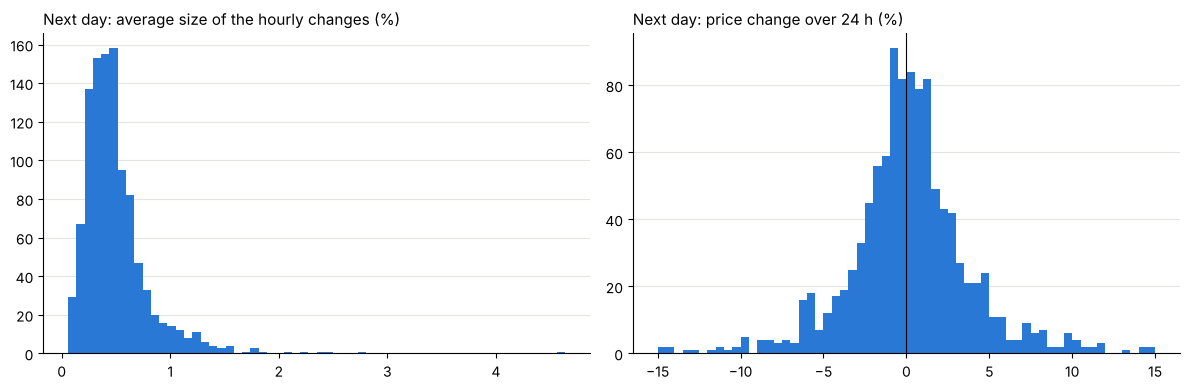

Share of up days in training: 0.515


,train size_next,train ret_next,val size_next,val ret_next
range_1d,0.652,0.069,0.530,0.032
size_1d,0.643,0.050,0.540,0.041
vol_1d,0.627,0.046,0.492,0.052
vol_7d,0.602,0.059,0.467,0.042
volume_ratio,0.181,0.010,0.226,0.000
ret_30d,0.005,0.021,0.212,0.021
ret_1d,-0.174,-0.094,0.098,-0.058
ret_7d,-0.202,-0.006,0.147,0.041
last_hour,-0.233,-0.083,-0.007,-0.022


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_days["size_next"], bins=60, color=BLUE)
tidy(axes[0], "Next day: average size of the hourly changes (%)")
axes[1].hist(train_days["ret_next"].clip(-15, 15), bins=60, color=BLUE)
axes[1].axvline(0, color="black", lw=0.8)
tidy(axes[1], "Next day: price change over 24 h (%)")
plt.tight_layout()
plt.show()

print("Share of up days in training:", round(train_days["up_next"].mean(), 3))
corr_next = pd.DataFrame({
    f"{block} {t}": d[num_cols].corrwith(d[t])
    for block, d in [("train", train_days), ("val", val_days)] for t in ["size_next", "ret_next"]
})
corr_next.round(3).sort_values("train size_next", ascending=False)

**What we see** *(this run, 1,795 train days and 547 validation days)*

- The price went up on **51.1%** of the training days, so up and down days are almost equally common (the classes are balanced).
- The next day's move size is skewed: the median day has 0.41% per hour, the mean is 0.48% and the wildest day 4.64%.
- **Move size:** today's volatility attributes are strongly correlated with tomorrow's move size: `size_1d` 0.69, `range_1d` 0.68, `vol_1d` 0.65 and `vol_7d` 0.63 on train, and 0.47–0.54 on validation. Weaker in the calmer validation block, but still strong: wild days tend to be followed by wild days ("volatility clustering"). Relative volume adds a little (+0.20 train, +0.23 validation).
- **The past direction and tomorrow's size: the sign flips.** On train, falls are followed by larger moves (`ret_1d` −0.14, `ret_7d` −0.16, `last_hour` −0.17). On validation, rises are (`ret_7d` +0.15, `ret_30d` +0.21, in the 2023–2024 bull market). A relation that changes sign between blocks should not be relied on.
- **Direction:** no attribute is useful for tomorrow's direction. All correlations with `ret_next` are between −0.08 and +0.04 on train and between −0.06 and +0.05 on validation. The largest, `ret_1d` (−0.084 on train, a small daily reversal), falls to −0.058 on validation (p ≈ 0.18).

This already suggests the answer: the **size** can be predicted, the **direction** hardly at all.

### 6.1 What kind of day was it? K-Means clusters

K-Means groups days by how the market behaved, **without** looking at the next day. Three attributes are used: the day's price change, its volatility and its volume compared with the week. They are standardised first, because K-Means uses distances.

**How many clusters?** The elbow method:

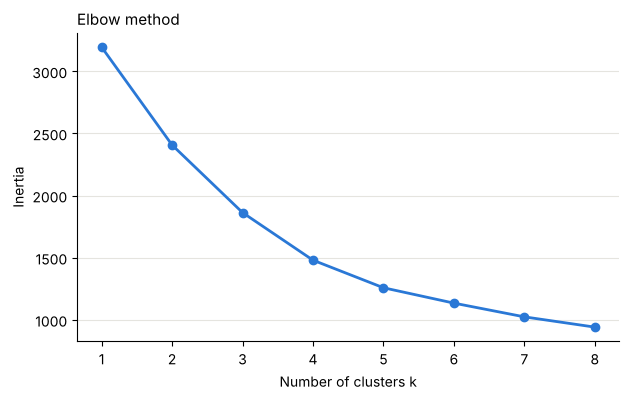

In [17]:
cluster_cols = ["ret_1d", "vol_1d", "volume_ratio"]
cluster_scaler = StandardScaler().fit(train_days[cluster_cols])
Z_train = cluster_scaler.transform(train_days[cluster_cols])

inertias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z_train).inertia_ for k in range(1, 9)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, 9), inertias, "o-", color=BLUE, lw=2)
ax.set_xlabel("Number of clusters k")
ax.set_ylabel("Inertia")
tidy(ax, "Elbow method")
plt.show()

**k = 4**, where the curve bends: the inertia drops by about 1,400, 950 and 630 up to k = 4, and by less than 300 per extra cluster after that. Each cluster is described by its centre in the original units. The cluster numbers depend on the run, so name them from the centres.

,ret_1d,vol_1d,volume_ratio,days (train)
0,0.319,0.476,-0.676,326
1,-1.176,0.614,0.065,499
2,5.265,0.887,0.207,188
3,-7.068,1.905,0.593,52


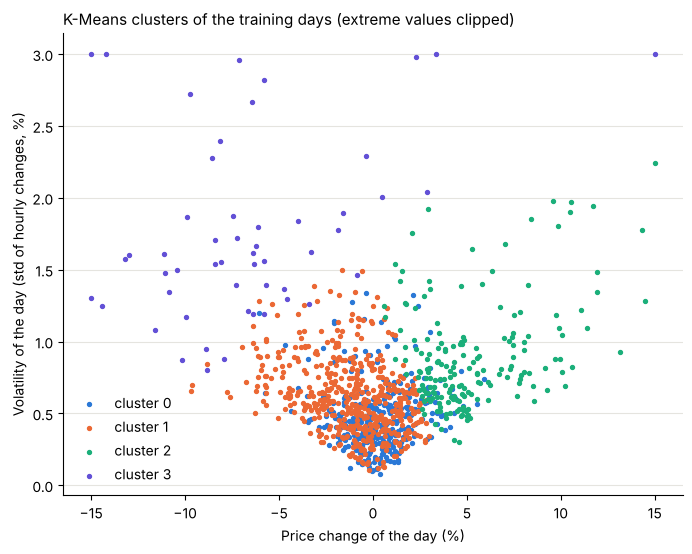

In [18]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(Z_train)

centres = pd.DataFrame(cluster_scaler.inverse_transform(kmeans.cluster_centers_), columns=cluster_cols)
centres["days (train)"] = np.bincount(kmeans.labels_)
display(centres.round(3))

cluster_colors = [BLUE, ORANGE, AQUA, "#6250d6"]
fig, ax = plt.subplots(figsize=(8, 6))
for k in range(4):
    part = train_days[kmeans.labels_ == k]
    ax.scatter(part["ret_1d"].clip(-15, 15), part["vol_1d"].clip(upper=3), s=8, color=cluster_colors[k], label=f"cluster {k}")
ax.set_xlabel("Price change of the day (%)")
ax.set_ylabel("Volatility of the day (std of hourly changes, %)")
ax.legend(frameon=False)
tidy(ax, "K-Means clusters of the training days (extreme values clipped)")
plt.show()

**Do the clusters say anything about the next day?** The validation days are assigned to the clusters learned on the training days, and the next day is compared:

In [19]:
val_clusters = kmeans.predict(cluster_scaler.transform(val_days[cluster_cols]))
summary = {}
for block, d, labels in [("train", train_days, kmeans.labels_), ("validation", val_days, val_clusters)]:
    summary[block] = d.assign(cluster=labels).groupby("cluster").agg(
        days=("up_next", "size"), next_day_move_size=("size_next", "mean"), next_day_up_share=("up_next", "mean"))
pd.concat(summary, axis=1).round(3)

train                     ...         validation                  
         days next_day_move_size  ... next_day_move_size next_day_up_share
cluster                           ...                                     
0         326              0.421  ...              0.263             0.511
1         499              0.463  ...              0.290             0.521
2         188              0.586  ...              0.418             0.418
3          52              1.022  ...              0.545             0.625

[4 rows x 6 columns]

**What we see** *(this run; cluster numbers are those of this run)*

- **Elbow:** the inertia falls quickly up to k = 4 and slowly after that, so 4 clusters is a reasonable choice.
- **The 4 clusters** are easy to name from their centres:
  - **normal days** (cluster 0): +0.05%, average volatility (0.54) and volume, **897** training days, half of them;
  - **quiet days** (cluster 2): +0.11%, low volatility (0.46), volume well below the weekly average (500 days);
  - **crash days** (cluster 1): −6.1%, high volatility (1.31), high volume (197 days);
  - **rally days** (cluster 3): +6.4%, high volatility (1.21), high volume (201 days).
- **The scatter plot:** crash and rally days are separated by the day's price change and by volatility. Quiet and normal days differ mainly in volume, which is not on the axes, so they overlap in the plot.

**The next day:**
- **Move size depends on the cluster:** after crash days (0.81%) and rally days (0.71%) the next day's moves are about **twice as big** as after quiet or normal days (0.40–0.41%). The same holds on validation (0.50% and 0.46% vs 0.27–0.29%), at a lower level because the block is calmer. Quiet days are not followed by calmer days than normal days: low volume alone does not signal calm.
- **Direction mostly does not:** the share of up days is 48–51% after quiet, normal and rally days. **Crash days are the exception:** 60.4% of the following days were up on train (119 of 197, p ≈ 0.01 against the 51.1% base rate) and 65% on validation, but on only 20 days (p ≈ 0.26). This hints at a rebound after crashes, the daily reversal also seen in 6.2, but the sample is small and 4 clusters were compared, so it is not a reliable signal.
- **Validation has far fewer extreme days:** 319 normal, 175 quiet, 33 rally and 20 crash days, against 22% crash or rally days on train.

Clustering is unsupervised: K-Means never saw the targets, yet it found groups that differ clearly in tomorrow's move size, and hardly in tomorrow's direction.

### 6.2 Volatility and trend regimes

*Idea from `bitcoin-models-v3.ipynb` (D4), here without any model.* The days are split by two conditions that are **known at the forecast origin**: the tercile of last week's volatility (`vol_7d`, cut points from the train days) and the 30-day trend (bull if the price rose over the last 30 days). For each regime: how big the next day's moves are, how often the next day is up, and whether today's change says anything about tomorrow's.

In [20]:
vol_cut = train_days["vol_7d"].quantile([1 / 3, 2 / 3]).values


def regime_table(d):
    vol = pd.Series(pd.cut(d["vol_7d"], [-np.inf, *vol_cut, np.inf], labels=["1 calm", "2 middle", "3 wild"]).astype(str), index=d.index)
    trend = pd.Series(np.where(d["ret_30d"] > 0, "bull (30d up)", "bear (30d down)"), index=d.index)
    rows = {}
    for kind, labels in [("volatility", vol), ("trend", trend)]:
        for lab in sorted(labels.unique()):
            g = d[labels == lab]
            rows[f"{kind}: {lab}"] = {"days": len(g), "next_day_move_size": g["size_next"].mean(),
                                      "next_day_up_share": g["up_next"].mean(),
                                      "corr(ret_1d, ret_next)": g["ret_1d"].corr(g["ret_next"])}
    return pd.DataFrame(rows).T


pd.concat({"train": regime_table(train_days), "validation": regime_table(val_days)}, axis=1).round(3)

train  ...             validation
                         days  ... corr(ret_1d, ret_next)
volatility: 1 calm      355.0  ...                 -0.010
volatility: 2 middle    355.0  ...                 -0.002
volatility: 3 wild      355.0  ...                 -0.292
trend: bear (30d down)  512.0  ...                 -0.050
trend: bull (30d up)    553.0  ...                 -0.077

[5 rows x 8 columns]

**What we see** *(this run)*

- **Volatility persists.** The next day's move size is 0.30% in the calm tercile, 0.44% in the middle one and 0.71% in the wild one on train (2.4×), and 0.27%, 0.39% and 0.47% on validation.
- **Validation is much calmer than train.** With the train cut points, 428 of the 547 validation days (78%) are "calm" and only 41 are "wild". A model calibrated on train volatility levels mostly sees calm days afterwards.
- **Direction:** the share of up days is 50–52% in every train regime. On validation the wild tercile has 65.9% up days, but on only 41 days (p ≈ 0.06).
- **The daily reversal sits in the wild days.** The correlation between today's and tomorrow's change is −0.14 in the wild tercile on train (p < 0.001) and −0.25 on validation (41 days, p ≈ 0.11), and about 0 in the calm tercile. On train it is also −0.14 in bear markets, but only −0.05 on validation, so it is not stable.
- **Trend:** the next day's move size and up share are almost the same in bull and bear markets.
- **Link to the models:** the in-sample reversal did not turn into usable skill: the best next-day direction model has AUC 0.513 on test (README). `bitcoin-models-v3.ipynb` (D4) also found the hourly return IC ≈ 0 in every regime: "there is no hidden regime where returns become predictable".

## 7. Other markets: Binance and ETH

*Descriptive, whole series.* The Binance hourly candles of BTCUSDT and ETHUSDT (`data/binance_*_1h.csv.gz`, from `utils/binance.py`) are a second source for Bitcoin and the main other crypto asset. Two questions:

1. **Does a second exchange agree with the base data?** Kaggle's data comes from Bitstamp (USD); Binance trades against USDT. If the hourly returns of both did not match, the base data would have a problem.
2. **How closely does ETH move with BTC, and does it lead it?**

`load_binance` fills the hours Binance has no data for (127 in 2018–2019) with the previous price, as in `v3-extensions.ipynb`.

In [21]:
bn_btc, bn_eth = load_binance("BTCUSDT"), load_binance("ETHUSDT")
both = pd.DataFrame({"btc_bitstamp": r, "btc_binance": bn_btc["ret"].reindex(r.index),
                     "eth": bn_eth["ret"].reindex(r.index)}).dropna()

diff = both["btc_bitstamp"] - both["btc_binance"]
print(f"Common hours: {len(both):,}   {both.index[0]} -> {both.index[-1]}")
print(f"corr(Bitstamp, Binance) hourly BTC returns: {both['btc_bitstamp'].corr(both['btc_binance']):.4f}")
print(f"mean |difference| {diff.abs().mean():.3f} pp, against an average |move| of {both['btc_bitstamp'].abs().mean():.3f}%; "
      f"hours differing by more than 1 pp: {(diff.abs() > 1).sum()}")

eth_years = {}
for y, d in both.groupby(both.index.year):
    eth_years[y] = {"corr BTC-ETH returns": d["btc_bitstamp"].corr(d["eth"]),
                    "corr BTC-ETH |returns|": d["btc_bitstamp"].abs().corr(d["eth"].abs()),
                    "ETH / BTC average |move|": d["eth"].abs().mean() / d["btc_bitstamp"].abs().mean()}
display(pd.DataFrame(eth_years).T.round(3))

Common hours: 59,331   2020-01-01 00:00:00 -> 2026-10-08 02:00:00
corr(Bitstamp, Binance) hourly BTC returns: 0.9934
mean |difference| 0.031 pp, against an average |move| of 0.393%; hours differing by more than 1 pp: 23


,corr BTC-ETH returns,corr BTC-ETH |returns|,ETH / BTC average |move|
2020,0.823,0.782,1.353
2021,0.832,0.756,1.270
2022,0.890,0.845,1.362
2023,0.854,0.812,1.116
2024,0.808,0.746,1.208
2025,0.802,0.723,1.637
2026,0.887,0.836,1.282


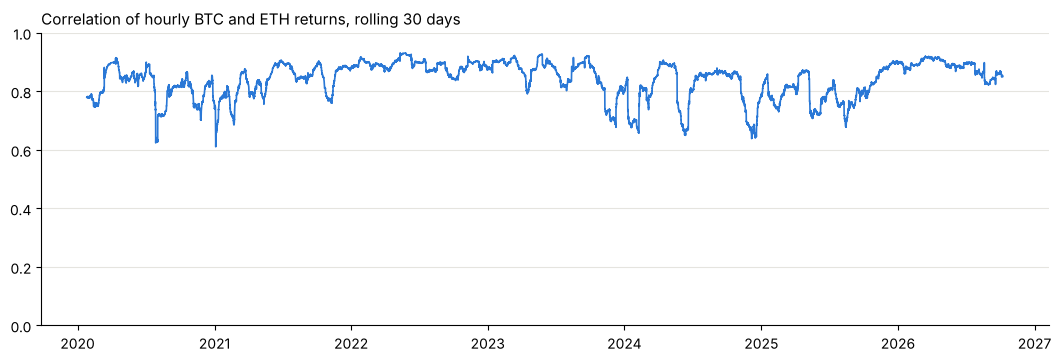

k (hours),-3,-2,-1,0,1,2,3
ETH,-0.0014,-0.0334,-0.0137,0.8428,-0.0059,-0.0216,-0.0069
BTC itself,-0.0055,-0.0298,-0.0270,NaN,-0.0270,-0.0298,-0.0055


In [22]:
roll_eth = both["btc_bitstamp"].rolling(720, min_periods=600).corr(both["eth"])
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(roll_eth.index, roll_eth, color=BLUE, lw=1.2)
ax.set_ylim(0, 1)
tidy(ax, "Correlation of hourly BTC and ETH returns, rolling 30 days")
plt.show()

# Lead-lag on the train block: corr(BTC_t, X_{t-k}); k > 0 means X leads BTC by k hours
tr = both.loc[:TRAIN_END]
lead = pd.DataFrame({
    "ETH": {k: tr["btc_bitstamp"].corr(tr["eth"].shift(k)) for k in range(-3, 4)},
    "BTC itself": {k: tr["btc_bitstamp"].corr(tr["btc_bitstamp"].shift(k)) if k else np.nan for k in range(-3, 4)},
})
lead.index.name = "k (hours)"
lead.round(4).T

**What we see** *(this run, whole series)*

- **The base data agrees with a second exchange.** Bitstamp's and Binance's hourly BTC returns correlate **0.982** over all 76,851 hours. The mean difference is 0.054 percentage points against an average move of 0.416%, and 162 hours (0.2%) differ by more than 1 point: small differences expected between two exchanges and two quote currencies (USD and USDT).
- **ETH moves with BTC.** The yearly correlation of hourly returns is 0.75–0.89 (highest in 2022 and 2026), and 0.68–0.85 for the size of the moves. The rolling 30-day correlation stays mostly between 0.75 and 0.93, with short dips to about 0.55–0.65 (e.g. late 2018, early 2019, 2024). ETH moves 1.12–1.64× as much as BTC (most in 2025).
- **ETH does not lead BTC.** The correlation is 0.817 in the same hour and within ±0.04 at every other lag. The lagged values (−0.038 at k = −2, −0.031 at k = 2) mirror BTC's own autocorrelation (−0.038 at lag 2): ETH's past says nothing about BTC that BTC's own past does not.
- **Link to the models** *(`v3-extensions.ipynb`)*: the Binance attributes (order flow, ETH, ETH vs BTC) do not change the results: Gradient Boosting's test R² for the move size stays at 0.121–0.126 against 0.123 without them, and the next-hour AUC is 0.537 with and without them.

## 8. Macroeconomic variables

*Section and texts from `Correlation Analyses/correlation_analyses.ipynb` and its results brief (`BTC_macro_correlation_results_brief.docx`). The BTC frames now come from the base data, so the analysis starts in **2020**, like the rest of the notebook (the correlation notebook and its brief start in 2017).*

Measures how BTC returns relate to ~40 macro and market variables (FRED, Yahoo Finance) at daily, weekly and monthly frequency.

Flow: BTC frames → macro panels → remove redundant variables → correlations → lead-lag → stability over time → size of the moves (8.6) → release days (8.7). Sections 8.3–8.5 describe what BTC moves *with*; 8.6–8.7 ask what could help *predict* it.

**Summary of this run** *(Jan 2018 → Oct 2026)*. BTC returns move moderately with risk assets and financial conditions: positively with stocks (S&P 500, Euro Stoxx 50), high-yield bonds (HYG), breakeven inflation and, at monthly frequency, net liquidity; negatively with the VIX, the dollar, the high-yield spread and tighter financial conditions (NFCI). The strongest correlations are 0.33 daily (S&P 500), 0.33 weekly (VIX) and 0.53 monthly (S&P 500). No variable leads BTC at daily or weekly horizons, the link with the size of BTC's moves is weak (8.6), and the relations are not stable: the S&P 500 correlation goes from 0.22 in 2020 to 0.56 in 2022, back to 0.23 in 2023 and up to 0.44 in 2026. This is the same picture as the results brief (`BTC_macro_correlation_results_brief.docx`, data from 2017), which stays the full write-up; its correlations are weaker because 2017–2019, years with almost no correlation, are included there.

Reference listed in the first version of the notebook: <https://arxiv.org/html/2407.13278v1>.

**Method** *(from the brief)*. Panels of log returns (rates and spreads as differences, computed after aligning to the panel frequency). Slow series (e.g. CPI) only enter slower panels (monthly); the daily panel uses weekdays only. Spearman correlation with the BTC return and with the return's absolute value; q-values from Benjamini–Hochberg false discovery rate correction. Lead-lag on an a-priori shortlist [SP500, DXY, US10Y, Gold, VIX, HY_OAS, NetLiquidity] (using availability-date alignment); stability checked with a sliding window.

### 8.1 Macro panels

Reads the macro and market variables from the frozen copy `data/macro_raw.csv.gz` and builds one panel per frequency, aligned by observation date (`pit=False`), so it measures co-movement rather than prediction. Each variable is transformed (log return or difference) after alignment, so slow series are never correlated with fine-grained data.

**Frozen copy.** FRED and Yahoo Finance have no fixed versions (series are revised, adjusted ETF prices change after every dividend) and the download cache is not in git, so two runs a week apart gave slightly different numbers. The first run downloads every series and saves them to `data/macro_raw.csv.gz` (`utils.macro.load_macro`); later runs, and every member of the group, read that file. Set `REFRESH_MACRO = True` in section 1 to download again; commit the new file through a pull request, like any change to `data/`.

**Note.** In this run the Yahoo Finance series (S&P 500, Nasdaq, VIX, DXY, gold, oil…) downloaded correctly (README, task 10), so the whole shortlist is available. NetLiquidity is a weekly series, so it only enters the weekly and monthly panels. The cell prints any skipped series: check it before reading the tables.

In [23]:
btc_close = {f: df["Close"] for f, df in frames_from_hourly(hourly).items()}
macro = load_macro(MACRO_FILE, refresh=REFRESH_MACRO, data_start=START)   # frozen copy (downloaded once)
last_obs = max(s.index.max() for s in macro.raw.values())
print(f"{len(macro.raw)} series from {MACRO_FILE}, last observation {last_obs.date()}")
panels, meta = build_panels(btc_close, macro, start=START)
print({f: p.shape for f, p in panels.items()})

43 series from data/macro_raw.csv.gz, last observation 2026-10-20
{'D': (1766, 31), 'W': (353, 36), 'ME': (81, 46)}


**Data coverage.** Shows the variables with the lowest fraction of non-missing observations in their panel. Low coverage may mean truncated history (e.g. licensed series on FRED) or a discontinued series. Check this before interpreting any correlation.

In [24]:
cov = pd.concat([p.drop(columns=list(TARGETS)).notna().mean() for p in panels.values()])
cov = cov.groupby(level=0).first()                          # finest panel where each variable appears
cov.sort_values().head(10).to_frame("fraction_with_data").join(meta[["source", "id", "group"]])

,fraction_with_data,source,id,group
HY_OAS,0.437146,FRED,BAMLH0A0HYM2,credit
ConsSentiment,0.987654,FRED,UMCSENT,activity
CorePCE,0.987654,FRED,PCEPILFE,inflation
CPI,0.987654,FRED,CPIAUCSL,inflation
PCE,0.987654,FRED,PCEPI,inflation
M2,0.987654,FRED,M2SL,liquidity
IndProd,0.987654,FRED,INDPRO,activity
CoreCPI,0.987654,FRED,CPILFESL,inflation
RetailSales,0.987654,FRED,RSAFS,activity
Payrolls,0.987654,FRED,PAYEMS,activity


### 8.2 Redundancy among macro variables

*(From `old_notebooks/correlation_analyses.ipynb`.)* First a look at how the macro variables relate to each other: the Spearman correlation between every pair of variables of the daily panel, ordered by hierarchical clustering (distance 1 − |r|) so that redundant variables sit next to each other. BTC is not in the plot.

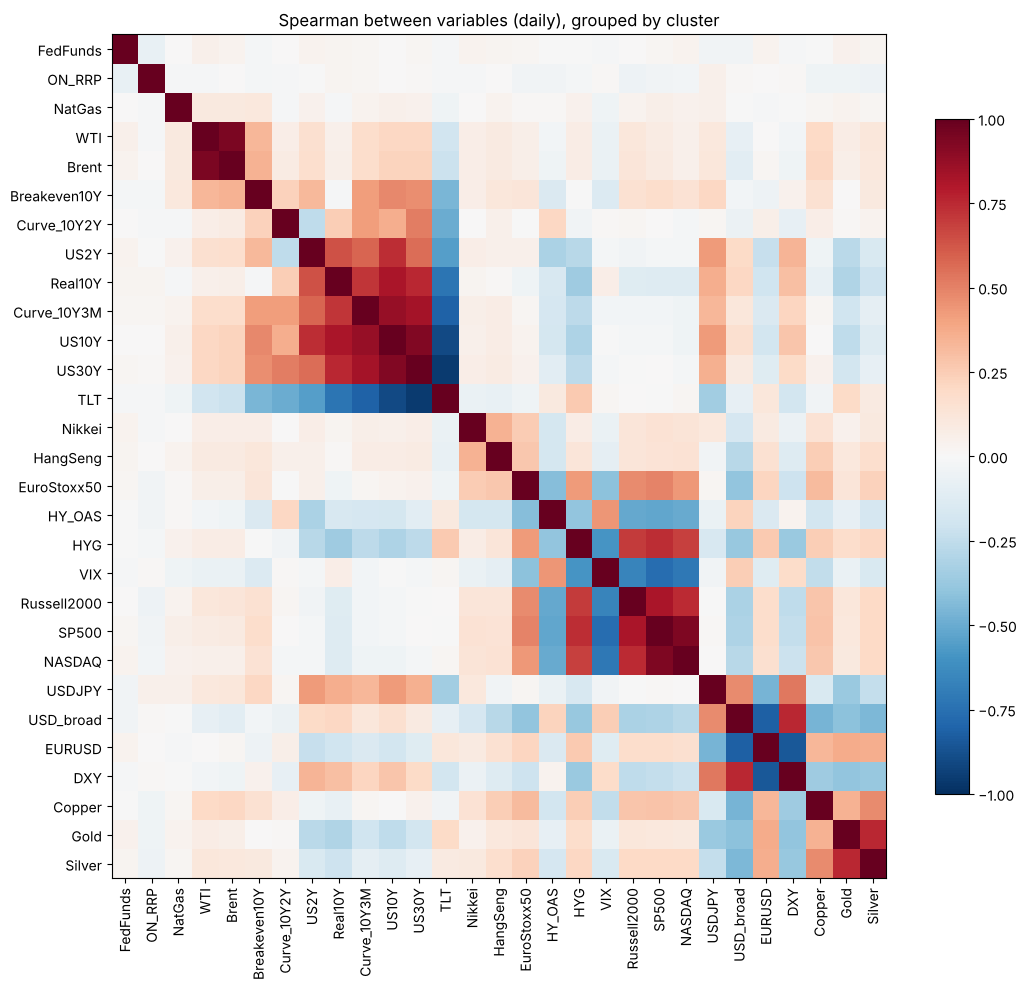

In [25]:
c = panels["D"].drop(columns=list(TARGETS)).corr(method=METHOD)
order = cluster_order(c)
heatmap(c.loc[order, order], "Spearman between variables (daily), grouped by cluster", vmax=1, annot=False, figsize=(11, 10))
plt.show()

The pruning below removes variables that are almost duplicates of another macro variable (|r| above `PRUNE_THRESHOLD`), keeping the one that is less redundant with the rest. Only the correlation between macro variables is used, never the one with BTC, so the pruning does not bias the results interpreted below. When two variables are redundant, the one in `FOCUS` is kept. The table lists what was dropped and which variable stands in for it.

In [26]:
panels, pruned = prune_panels(panels, threshold=PRUNE_THRESHOLD, method=METHOD, prefer=FOCUS)
display(pruned.round(2))
print({f: p.shape[1] - len(TARGETS) for f, p in panels.items()}, "variables kept per panel")

,kept_instead,abs_r,panel
US30Y,TLT,0.96,D
Brent,WTI,0.94,D
NASDAQ,SP500,0.93,D
TLT,US10Y,0.90,D
Curve_10Y3M,US10Y,0.87,D
EURUSD,DXY,0.85,D
Real10Y,US10Y,0.82,D
Russell2000,SP500,0.81,D
CPI,PCE,0.87,ME


{'D': 21, 'W': 26, 'ME': 35} variables kept per panel


### 8.3 Correlations with BTC

Ranks every remaining variable by its correlation with the BTC return (`r_ret`) and with its absolute value (`r_abs`), i.e. the size of the move rather than its direction. `q_*` is the p-value adjusted for multiple comparisons (FDR): with this many variables, several would look significant by chance alone. Monthly results rest on ~100 observations, so treat them with extra caution.

In [27]:
for f, name in {"D": "DAILY (weekdays)", "W": "WEEKLY", "ME": "MONTHLY"}.items():
    print(f"\n=== {name} ===")
    display(corr_summary(panels[f], METHOD).round(3).head(TOP))


=== DAILY (weekdays) ===


,n,r_ret,q_ret,r_abs,q_abs
var,,,,,
SP500,1765,0.331,0.000,-0.040,0.436
VIX,1765,-0.292,0.000,0.064,0.153
HYG,1765,0.286,0.000,-0.048,0.436
HY_OAS,772,-0.260,0.000,-0.016,0.923
USD_broad,1765,-0.198,0.000,-0.026,0.829
EuroStoxx50,1765,0.191,0.000,-0.003,0.935
Silver,1765,0.186,0.000,0.039,0.436
DXY,1765,-0.171,0.000,-0.008,0.935
Copper,1765,0.170,0.000,0.015,0.923



=== WEEKLY ===


,n,r_ret,q_ret,r_abs,q_abs
var,,,,,
VIX,352,-0.334,0.000,0.101,0.309
SP500,352,0.317,0.000,-0.102,0.309
HY_OAS,153,-0.296,0.001,0.104,0.489
EuroStoxx50,352,0.250,0.000,-0.130,0.187
HYG,352,0.244,0.000,-0.095,0.329
NFCI,352,-0.209,0.000,0.073,0.489
Nikkei,352,0.173,0.004,-0.062,0.489
Copper,352,0.169,0.004,0.010,0.960
USD_broad,352,-0.167,0.004,0.050,0.586



=== MONTHLY ===


,n,r_ret,q_ret,r_abs,q_abs
var,,,,,
SP500,80,0.528,0.000,0.143,0.641
Breakeven10Y,80,0.440,0.001,-0.059,0.847
HYG,80,0.384,0.005,0.189,0.492
NetLiquidity,80,0.363,0.008,0.236,0.323
VIX,80,-0.352,0.009,-0.237,0.323
EuroStoxx50,80,0.316,0.024,0.169,0.569
NFCI,80,-0.307,0.027,0.000,0.998
USD_broad,80,-0.269,0.068,-0.089,0.847
ON_RRP,80,-0.264,0.068,-0.059,0.847


**What we see** *(this run: 1,765 daily (weekdays), 352 weekly and 80 monthly observations, Jan 2020 → Oct 2026)*

The pruning keeps 21 daily, 26 weekly and 35 monthly variables. Russell 2000 and Nasdaq are dropped as near-duplicates of the S&P 500 (|r| 0.81 and 0.93), EURUSD of DXY, and TLT, the real yield and the 10Y–3M curve of US10Y. The strongest correlations with the BTC return ((!) = partial history):

| Frequency | Variable | n | r_ret | q_ret | r_abs | q_abs |
|---|---|---|---|---|---|---|
| Daily | SP500 | 1765 | 0.331 | <0.001 | −0.040 | 0.436 |
| Daily | VIX | 1765 | −0.292 | <0.001 | 0.064 | 0.153 |
| Daily | HYG | 1765 | 0.286 | <0.001 | −0.048 | 0.436 |
| Daily | HY_OAS | 772 (!) | −0.260 | <0.001 | −0.016 | 0.923 |
| Weekly | VIX | 352 | −0.334 | <0.001 | 0.101 | 0.309 |
| Weekly | SP500 | 352 | 0.317 | <0.001 | −0.102 | 0.309 |
| Weekly | HY_OAS | 153 (!) | −0.296 | 0.001 | 0.104 | 0.489 |
| Monthly | SP500 | 80 | 0.528 | <0.001 | 0.143 | 0.641 |
| Monthly | Breakeven10Y | 80 | 0.440 | 0.001 | −0.059 | 0.847 |
| Monthly | HYG | 80 | 0.384 | 0.005 | 0.189 | 0.492 |

- **One risk-appetite pattern.** BTC rises with stocks (S&P 500, Euro Stoxx 50, Nikkei, Hang Seng), high-yield bonds (HYG) and metals (copper, silver, gold), and falls with the VIX, the dollar (DXY, broad dollar index), the high-yield spread and NFCI.
- **Daily:** 11 of the 12 variables in the table have q < 0.05 (Hang Seng: q = 0.065). The correlations are moderate: the strongest, the S&P 500 at 0.33, accounts for about 11% of the variation in BTC's daily ranks.
- **Weekly:** the same variables, with the VIX (−0.33) and the S&P 500 (0.32) on top and NFCI (−0.21) appearing; all 12 have q ≤ 0.011.
- **Monthly:** the S&P 500 is the strongest (r = 0.53), followed by breakeven inflation (0.44), HYG (0.38), net liquidity (0.36), the VIX (−0.35), Euro Stoxx 50 (0.32) and NFCI (−0.31), all with q < 0.05. The dollar is not significant (q ≥ 0.068). With 80 observations the uncertainty is large: the 95% interval of r = 0.53 is about 0.35–0.67.
- **HY_OAS** covers only the period since 2023 (44% coverage, 772 and 153 observations; FRED keeps only a rolling three-year window of this series, so it loses its oldest days with every download), so it cannot be compared directly with the rest.
- **The direction of the macro moves says nothing about the size of BTC's moves:** q_abs is at least 0.15 daily, 0.19 weekly and 0.32 monthly; the largest |r_abs| is 0.24 (VIX and net liquidity, monthly). This column correlates |BTC| with the *signed* change of each variable; whether big BTC moves come with *big* macro moves is tested in 8.6.
- **Compared with the brief** (data from 2017): same variables and signs, but stronger correlations here (S&P 500 daily 0.331 vs 0.236, monthly 0.528 vs 0.366), because 2017–2019, years with almost no correlation, are left out. Russell 2000, the top daily variable of the brief, is pruned here and represented by the S&P 500.

### 8.4 Lead-lag

Uses panels built with `pit=True` (availability date), so each value only appears when it was actually known, for the shortlist in `FOCUS` (variables pruned above are replaced by the one kept instead). Shows the correlation between BTC returns and each variable shifted by k periods; k > 0 means the variable leads BTC. A stronger correlation at k > 0 than at k = 0 would suggest predictive content; a peak only at k = 0 is just co-movement.

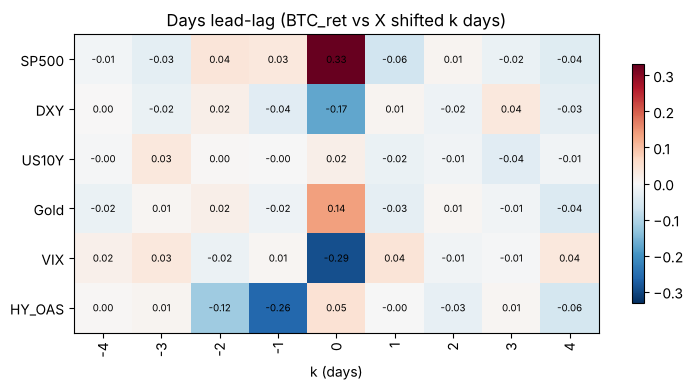

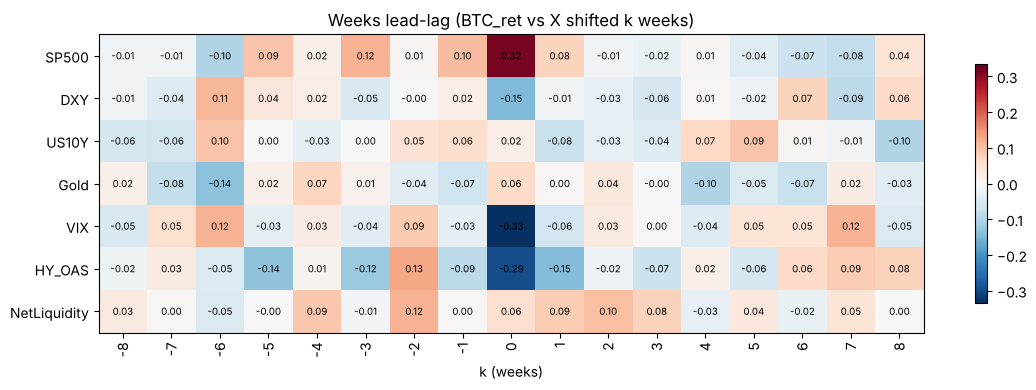

In [28]:
focus = resolve_focus(FOCUS, panels, pruned)
kept = sorted({c for p in panels.values() for c in p.columns} - set(TARGETS))
panels_pit, _ = build_panels(btc_close, macro, pit=True, freqs=tuple(MAX_LAG), start=START, variables=kept)

units = {"D": "days", "W": "weeks"}
for f, k in MAX_LAG.items():
    vars_f = [v for v in focus if v in panels_pit[f].columns]
    heatmap(lead_lag(panels_pit[f], max_lag=k, variables=vars_f, method=METHOD),
            f"{units[f].capitalize()} lead-lag (BTC_ret vs X shifted k {units[f]})", xlabel=f"k ({units[f]})")
plt.show()

**What we see** *(this run)*

- **Daily:** every variable peaks at k = 0 (S&P 500 0.33, VIX −0.29, DXY −0.17, Gold 0.14; US10Y about 0), and all values at k > 0 are within ±0.06. None of them leads BTC.
- **HY_OAS** peaks at k = −1 (−0.26, and −0.12 at k = −2) and is only 0.05 at k = 0. With availability-date alignment its value appears one or two days after the market day it describes, so this is its same-day correlation shifted by the publication lag, not BTC leading credit spreads.
- **Weekly:** the strongest cells are again at k = 0 (VIX −0.33, S&P 500 0.32, HY_OAS −0.29, DXY −0.15). The largest cells with k > 0 are HY_OAS at k = 1 (−0.15, inside the 5% band of ±0.16 for its 153 weeks), the VIX at k = 7 (+0.12, just outside the ±0.10 band for 352 weeks), and US10Y at k = 8, Gold at k = 4 and net liquidity at k = 2 (about ±0.10). With 56 cells at k > 0, about 3 would cross the band by chance, and these are isolated values with no pattern across neighbouring lags: noise.
- **NetLiquidity** is only 0.06 at k = 0 in the weekly panel but 0.36 in the monthly table: its relation with BTC appears only at slow frequency.

The macro variables move *together* with BTC, they do not move *before* it. A formal test (Granger causality, README task 11) is still pending.

### 8.5 Stability over time

Tests whether the correlation with BTC stays similar through time or changes between regimes, for the same shortlist (daily panel). Plots a rolling correlation (Pearson, absolute value) and tabulates the Spearman correlation per calendar year. With ~250 daily observations per year, small differences between years may be noise rather than a real regime change.

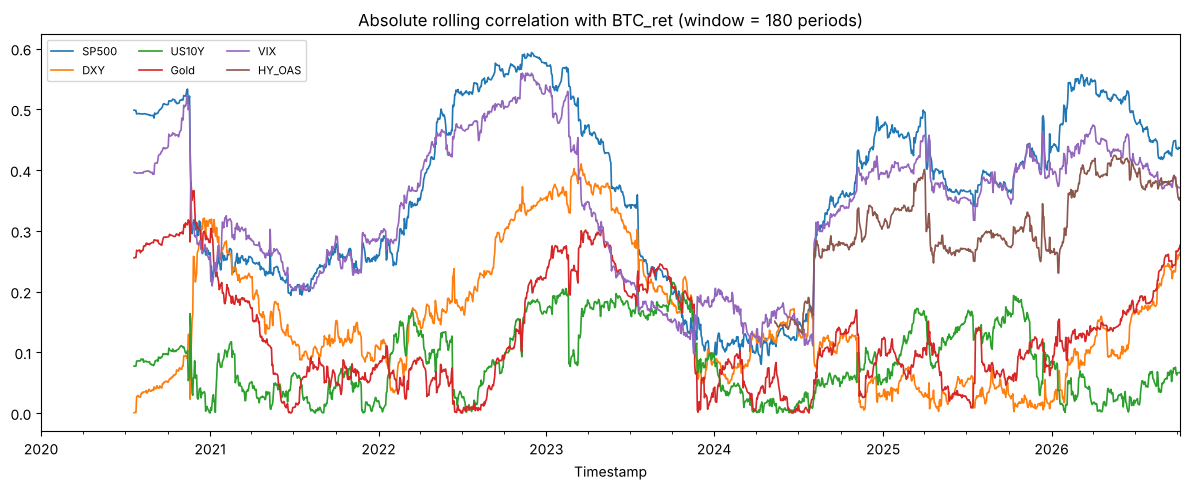

,SP500,DXY,US10Y,Gold,VIX,HY_OAS
2020,0.22,-0.12,0.08,0.31,-0.21,NaN
2021,0.25,-0.11,0.06,-0.07,-0.24,NaN
2022,0.56,-0.32,-0.06,0.09,-0.49,NaN
2023,0.23,-0.14,-0.06,0.09,-0.22,-0.26
2024,0.31,-0.18,0.01,0.15,-0.20,-0.17
2025,0.38,-0.08,0.08,0.10,-0.38,-0.30
2026,0.44,-0.24,-0.16,0.33,-0.31,-0.33


In [29]:
vars_d = [v for v in focus if v in panels["D"].columns]
rolling_corr_plot(panels["D"], vars_d, window=ROLL_WINDOW, absolute=True)
plt.show()
corr_by_year(panels["D"], vars_d, method=METHOD).round(2)

**What we see** *(this run)*

- **The relations are not stable.** The rolling correlation (180 days, Pearson, absolute value) with the S&P 500 and the VIX starts at about 0.4–0.5 in mid-2020 (the window still contains the March 2020 crash), drops sharply in late November 2020, stays at 0.2–0.3 in 2021, peaks at about 0.59 around the end of 2022, falls to 0.1–0.15 at the end of 2023 and early 2024, and returns to 0.35–0.55 from August 2024 to 2026.
- **The yearly Spearman correlations confirm it.** S&P 500: 0.22–0.25 (2020–2021), **0.56 (2022)**, 0.23 (2023), then rising again: 0.31, 0.38 and 0.44 (2024–2026). The VIX mirrors it (−0.49 in 2022, −0.38 in 2025). DXY is negative in every year (−0.08 to −0.32, strongest in 2022). US10Y stays close to zero (−0.16 to +0.08). Gold is strong only in 2020 (0.31) and 2026 (0.33). HY_OAS, available since 2023, is between −0.17 and −0.33, strongest in 2025–2026.
- **The abrupt steps are single days.** The March 2020 crash leaves the 180-day window about 36 weeks later, which is the sudden drop in late November 2020; the step in August 2024 is another extreme period entering the window. This is a known sensitivity of the Pearson correlation used in the plot; the yearly Spearman table is more robust.
- **The S&P 500 and the VIX move together,** so they are one risk-appetite factor, not two separate pieces of information. The link is strongest in stress years (2020, 2022) and in 2025–2026.
- **Consequence:** a correlation estimated on the train years would not describe the later years. A macro feature for the models would need recent windows.

### 8.6 Size of the moves: does BTC move more when markets are stressed?

The `r_abs` column of 8.3 correlates the size of BTC's move with the *signed* change of each variable, so it only asks whether big BTC moves come with rises or with falls of that variable. The question that matters for the size is a different one: do big BTC moves come with **big moves of the variable, in either direction**, and with **high levels of market stress**?

- **Co-volatility in the same period:** Spearman correlation between |BTC return| and |change of X| (`size_summary`), daily, weekly and monthly, with FDR-adjusted q-values. In the daily panel the correlation is computed **within weekdays**: BTC's Monday return covers Friday → Monday, so |BTC| is larger on Mondays, and any variable whose size has a weekday pattern would otherwise correlate with it for that reason alone (`weekday_rank_corr`).
- **Previous period:** the same with X's move of the previous day or week, on the availability-date panels of 8.4, so the value was public before BTC's period started.
- **Stress levels known in advance:** |BTC return| against the level of the VIX, NFCI and the high-yield spread at the end of the previous day or week, and the mean size of BTC's moves per quintile of the VIX level (a check that also shows non-linear shapes).

A positive answer is not yet a forecast: BTC's own recent volatility may already carry the same information, which only an out-of-sample test in the model notebooks can settle.

In [30]:
for f, name in {"D": "DAILY (weekdays)", "W": "WEEKLY", "ME": "MONTHLY"}.items():
    print(f"\n=== {name}: |BTC return| vs |change of X|, same period ===")
    display(size_summary(panels[f], lag=0, method=METHOD, within_weekday=(f == "D")).round(3).head(TOP))
for f in MAX_LAG:
    print(f"\n=== {units[f].upper()}: |BTC return| vs |change of X| in the previous {units[f][:-1]} (availability dates) ===")
    display(size_summary(panels_pit[f], lag=1, method=METHOD, within_weekday=(f == "D")).round(3).head(TOP))


=== DAILY (weekdays): |BTC return| vs |change of X|, same period ===


,n,r,q
var,,,
VIX,1765,0.132,0.000
SP500,1765,0.122,0.000
HY_OAS,772,0.119,0.003
EuroStoxx50,1765,0.091,0.001
Breakeven10Y,1765,0.088,0.001
US10Y,1765,0.079,0.003
DXY,1765,0.075,0.005
Copper,1765,0.063,0.020
Curve_10Y2Y,1765,0.059,0.030



=== WEEKLY: |BTC return| vs |change of X|, same period ===


,n,r,q
var,,,
DXY,352,0.146,0.093
Gold,352,0.143,0.093
VIX,352,0.120,0.193
US2Y,352,-0.111,0.193
FedBalanceSheet,352,0.108,0.193
Nikkei,352,0.107,0.193
EuroStoxx50,352,0.093,0.306
FedFunds,352,0.082,0.410
HY_OAS,153,0.078,0.802



=== MONTHLY: |BTC return| vs |change of X|, same period ===


,n,r,q
var,,,
FedBalanceSheet,80,0.277,0.257
EuroStoxx50,80,0.252,0.257
Payrolls,80,0.243,0.257
DXY,80,-0.237,0.257
VIX,80,0.233,0.257
M2,80,0.204,0.383
ConsSentiment,80,0.198,0.383
IndProd,80,0.180,0.465
HYG,80,0.155,0.637



=== DAYS: |BTC return| vs |change of X| in the previous day (availability dates) ===


,n,r,q
var,,,
Copper,1764,0.073,0.045
EuroStoxx50,1764,0.065,0.045
VIX,1764,0.065,0.045
Breakeven10Y,1764,0.060,0.054
US2Y,1764,-0.059,0.054
US10Y,1764,-0.053,0.095
ON_RRP,1764,0.051,0.100
SP500,1764,0.020,0.902
Gold,1764,0.020,0.902



=== WEEKS: |BTC return| vs |change of X| in the previous week (availability dates) ===


,n,r,q
var,,,
US2Y,351,-0.112,0.602
USD_broad,351,-0.106,0.602
Jobless_claims,351,0.078,0.947
USDJPY,351,-0.069,0.947
ON_RRP,351,-0.068,0.947
Breakeven10Y,351,0.060,0.947
NetLiquidity,351,-0.058,0.947
FedBalanceSheet,351,0.055,0.947
NatGas,351,-0.050,0.947


n      r      q
days  VIX     1765.0  0.074  0.005
      NFCI    1765.0 -0.108  0.000
      HY_OAS   771.0  0.069  0.068
weeks VIX      352.0  0.113  0.051
      NFCI     352.0 -0.155  0.007
      HY_OAS   153.0  0.024  0.771

,vix_from,vix_to,days,mean_btc_abs,median_btc_abs
quintile,,,,,
Q1,11.86,15.22,353,2.23,1.51
Q2,15.23,17.28,355,2.24,1.57
Q3,17.29,20.33,351,2.20,1.70
Q4,20.34,25.07,354,3.06,2.08
Q5,25.09,82.69,352,2.99,1.76


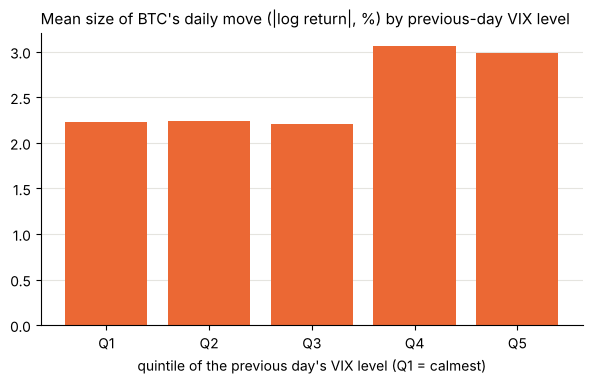

In [31]:
STRESS = ["VIX", "NFCI", "HY_OAS"]   # levels of market stress
rows, lv_daily = {}, None
for f in MAX_LAG:
    # level known at the end of the previous period: .shift(1) on an availability-date panel
    lv = level_panel(btc_close[f], macro, STRESS, freq=f, pit=True, start=START).shift(1)
    lv_daily = lv if f == "D" else lv_daily
    for v in lv.columns:
        d = pd.concat([panels[f]["BTC_absret"], lv[v]], axis=1, join="inner").dropna()
        rho, p = weekday_rank_corr(d.iloc[:, 0], d.iloc[:, 1])[:2] if f == "D" else stats.spearmanr(d.iloc[:, 0], d.iloc[:, 1])
        rows[(units[f], v)] = {"n": len(d), "r": rho, "p": p}
stress = pd.DataFrame(rows).T
stress["q"] = stats.false_discovery_control(stress["p"].astype(float))
display(stress.drop(columns="p").astype(float).round(3))

# mean size of BTC's daily move per quintile of the previous day's VIX level
d = pd.concat([panels["D"]["BTC_absret"] * 100, lv_daily["VIX"]], axis=1, join="inner").dropna()
d.columns = ["btc_abs", "vix"]
d["quintile"] = pd.qcut(d["vix"], 5, labels=[f"Q{i}" for i in range(1, 6)])
g = d.groupby("quintile", observed=True).agg(vix_from=("vix", "min"), vix_to=("vix", "max"),
                                              days=("btc_abs", "size"), mean_btc_abs=("btc_abs", "mean"),
                                              median_btc_abs=("btc_abs", "median"))
display(g.round(2))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(g.index.astype(str), g["mean_btc_abs"], color=ORANGE)
ax.set_xlabel("quintile of the previous day's VIX level (Q1 = calmest)")
tidy(ax, "Mean size of BTC's daily move (|log return|, %) by previous-day VIX level")
plt.show()

**What we see** *(this run, frozen macro data of 20 Oct 2026)*

- **Big BTC days come with big market days, but the link is weak.** In the daily panel (within weekdays) the size of BTC's move correlates with the size of the move of the VIX (0.13), the S&P 500 (0.12), the high-yield spread (0.12, 772 days since 2023), Euro Stoxx 50 (0.09), breakeven inflation (0.09), US10Y (0.08) and the dollar (0.08); 11 variables have q < 0.05. A correlation of 0.13 means under 2% of the variation in BTC's daily ranks. At weekly and monthly frequency nothing reaches q < 0.05 (strongest: dollar and gold weekly, 0.15 and 0.14, q = 0.093).
- **Little comes in advance.** With the previous day's macro moves the strongest values are copper (0.073), Euro Stoxx 50 (0.065) and the VIX (0.065), all at q = 0.045: just significant, and very small. With the previous week's, nothing comes close (q ≥ 0.60).
- **Market stress matters only above a threshold.** By quintile of the previous day's VIX level, BTC's mean daily move is 2.23%, 2.24% and 2.20% in the three calmest quintiles (VIX up to about 20) and 3.06% and 2.99% in the two most stressed ones (medians 1.51%, 1.57%, 1.70%, 2.08%, 1.76%). So BTC moves about a third more on days after a stressed stock market, and no differently between calm and normal ones. This is the kind of non-linear shape a correlation underrates: the rank correlation is only 0.07 daily (q = 0.005) and 0.11 weekly (q = 0.051).
- **NFCI is probably a trend.** Looser financial conditions go with bigger BTC moves (−0.11 daily, q < 0.001; −0.16 weekly, q = 0.007). Both the NFCI level and BTC's volatility move slowly over the years (BTC's average move fell from 2020–2022 to 2023–2026, section 2), so a correlation between two slow-moving series can come from that common drift rather than from a day-to-day link.
- **Correction of 8.3.** The earlier "no variable is related to the size of BTC's moves" came from testing the signed macro change. Tested properly there is a relation, but it is small, mostly same-day, and for stress levels it only appears above a VIX of about 20.

### 8.7 Release days: CPI, payrolls and FOMC

Monthly macro data reaches an hourly market through **scheduled releases**: US CPI and the employment report (payrolls) at 08:30 New York time (12:30 or 13:30 UTC, depending on daylight saving), and the FOMC statement at 14:00 New York time (18:00 or 19:00 UTC). The release dates are in `data/release_dates.csv` (281 releases, 2018 → Oct 2026; this analysis uses the 145 from 2020 in the train and validation blocks), built from the BLS release archives and the Federal Reserve's FOMC calendars; the file header lists the sources and the exclusions (notation votes, the October 2025 releases cancelled by the government shutdown).

For each release, the size of BTC's move in the hourly candle that contains it is compared with the **same clock hour on nearby weekdays without any release** (±7 days), so the comparison is not distorted by calm or wild periods. The ratio is the sum of the moves on release days divided by the sum of the matched reference moves; the p-value is a one-sided Wilcoxon signed-rank test on the paired differences. The same is done for the hours around the release and for the whole UTC day. This only needs BTC data, and like every analysis that could steer a model it uses the **train block, checked on validation**; the test block is left out.

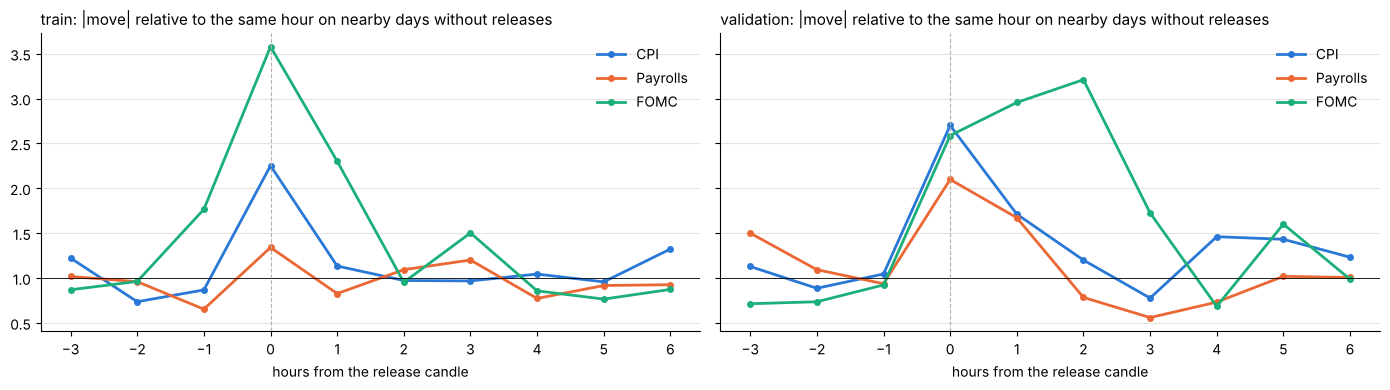

-3    -2    -1     0  ...     3     4     5     6
train      CPI           1.22  0.74  0.87  2.25  ...  0.97  1.04  0.96  1.32
           FOMC          0.87  0.96  1.77  3.58  ...  1.50  0.86  0.76  0.87
           Payrolls      1.02  0.96  0.65  1.34  ...  1.20  0.77  0.92  0.93
           all releases  1.04  0.88  1.03  2.24  ...  1.18  0.89  0.88  1.04
validation CPI           1.13  0.89  1.04  2.70  ...  0.78  1.46  1.43  1.23
           FOMC          0.71  0.74  0.92  2.59  ...  1.73  0.68  1.60  0.99
           Payrolls      1.50  1.09  0.94  2.10  ...  0.56  0.73  1.02  1.01
           all releases  1.09  0.90  0.97  2.46  ...  0.86  1.03  1.30  1.09

[8 rows x 10 columns]

In [32]:
rel = pd.read_csv(RELEASES_FILE, parse_dates=["date", "timestamp_utc"])
rel["hour"] = rel["timestamp_utc"].dt.floor("h")              # hourly candle that contains the release
absr = r.abs()
release_days = pd.DatetimeIndex(rel["timestamp_utc"].dt.normalize().unique())
quiet_hour = (absr.index.dayofweek < 5) & ~absr.index.normalize().isin(release_days)   # weekday, no release that day
BLOCKS = {"train": (r.index[0], TRAIN_END), "validation": (TRAIN_END + ONE_HOUR, VAL_END)}
OFFSETS = range(-3, 7)                                         # hours around the release candle


def matched(ts, window=pd.Timedelta(days=7)):
    """Mean |r| at the same clock hour on weekdays without releases within +-7 days of ts."""
    near = absr[(absr.index >= ts - window) & (absr.index <= ts + window) & quiet_hour]
    near = near[near.index.hour == ts.hour]
    return near.mean() if len(near) >= 3 else np.nan


def day_mean(d0):
    return absr.loc[d0:d0 + pd.Timedelta(hours=23)].mean()


def matched_day(ts):
    """Mean |r| of the same weekday one week before and after, if those days had no release."""
    days = [ts.normalize() + pd.Timedelta(days=k) for k in (-7, 7)]
    vals = [day_mean(d0) for d0 in days if d0 not in release_days]
    return np.mean(vals) if vals else np.nan


rows, profiles = {}, {}
for block, (a, b) in BLOCKS.items():
    in_block = rel[(rel["hour"] >= a) & (rel["hour"] <= b)]
    for ev, g in [*in_block.groupby("event"), ("all releases", in_block)]:
        # release hour
        ev_abs = absr.reindex(g["hour"]).to_numpy()
        ref = np.array([matched(t) for t in g["hour"]])
        ok = ~np.isnan(ev_abs) & ~np.isnan(ref)
        w = stats.wilcoxon(ev_abs[ok], ref[ok], alternative="greater")
        # whole UTC day of the release vs the same weekdays nearby
        day_ev = np.array([day_mean(t.normalize()) for t in g["hour"]])
        day_ref = np.array([matched_day(t) for t in g["hour"]])
        okd = ~np.isnan(day_ref)
        rows[(block, ev)] = {"releases": int(ok.sum()), "release hour |r| %": ev_abs[ok].mean(),
                             "matched hour |r| %": ref[ok].mean(), "ratio hour": ev_abs[ok].sum() / ref[ok].sum(),
                             "median ratio hour": np.median(ev_abs[ok] / ref[ok]),
                             "p (Wilcoxon)": w.pvalue, "ratio whole day": day_ev[okd].sum() / day_ref[okd].sum()}
        # profile around the release
        profiles[(block, ev)] = pd.Series({k: np.nansum(absr.reindex(g["hour"] + k * ONE_HOUR).to_numpy())
                                           / np.nansum([matched(t + k * ONE_HOUR) for t in g["hour"]]) for k in OFFSETS})

events_tab = pd.DataFrame(rows).T
single = events_tab.index.get_level_values(1) != "all releases"
events_tab.loc[single, "q (FDR, 6 tests)"] = stats.false_discovery_control(events_tab.loc[single, "p (Wilcoxon)"].astype(float))
display(events_tab.style.format({"releases": "{:.0f}", "release hour |r| %": "{:.3f}", "matched hour |r| %": "{:.3f}",
                                 "ratio hour": "{:.2f}", "median ratio hour": "{:.2f}", "p (Wilcoxon)": "{:.3f}",
                                 "ratio whole day": "{:.2f}", "q (FDR, 6 tests)": "{:.3f}"}, na_rep=""))

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a_, block in zip(ax, BLOCKS):
    for ev, c in zip(["CPI", "Payrolls", "FOMC"], [BLUE, ORANGE, AQUA]):
        p_ = profiles[(block, ev)]
        a_.plot(p_.index, p_.values, marker="o", ms=4, lw=2, color=c, label=ev)
    a_.axhline(1, c="k", lw=0.6)
    a_.axvline(0, c=GREY, lw=0.8, ls="--")
    a_.set_xticks(list(OFFSETS))
    a_.set_xlabel("hours from the release candle")
    a_.legend(frameon=False)
    tidy(a_, f"{block}: |move| relative to the same hour on nearby days without releases")
plt.tight_layout()
plt.show()
display(pd.DataFrame(profiles).T.round(2))   # ratio per hour from the release candle (0 = release hour)

In [33]:
# How much of the 12-15 UTC activity comes from release days? Mean |r| per hour on all weekdays vs
# on weekdays without releases, relative to the average hour of the block.
cmp = {}
for block, (a, b) in BLOCKS.items():
    s = absr.loc[a:b]
    wk = s[s.index.dayofweek < 5]
    q_ = s[quiet_hour[(absr.index >= a) & (absr.index <= b)]]
    base = wk.mean()
    cmp[(block, "all weekdays")] = wk.groupby(wk.index.hour).mean() / base
    cmp[(block, "weekdays without releases")] = q_.groupby(q_.index.hour).mean() / base
cmp = pd.DataFrame(cmp).T
display(cmp.loc[:, 11:20].round(2))

Timestamp                               11    12    13  ...    18    19    20
train      all weekdays               0.94  1.16  1.23  ...  0.98  0.97  1.02
           weekdays without releases  0.95  1.11  1.20  ...  0.93  0.94  1.01
validation all weekdays               0.85  1.03  1.20  ...  1.19  1.24  1.14
           weekdays without releases  0.84  0.91  1.17  ...  1.13  1.17  1.02

[4 rows x 10 columns]

**What we see** *(this run; train 97 releases, validation 48)*

- **BTC reacts to US macro releases in the release hour, in both blocks.** Pooled over all releases, BTC's move in the release candle is **2.24×** the move at the same hour on nearby days without releases on train and **2.46×** on validation (one-sided Wilcoxon p < 0.001 in both). The median ratios, 1.48 and 1.60, show that this is typical, not driven by a few big reactions.
- **FOMC is the strongest and the longest.** The FOMC statement moves BTC 3.58× a normal hour on train (median 2.26, q = 0.003) and 2.59× on validation (median 1.99, q = 0.031). The effect starts in the hour before (1.77× on train) and lasts two to three hours (2.30× one hour after on train; 3.0× and 3.2× one and two hours after on validation), the time of the press conference half an hour after the statement.
- **CPI and payrolls react less.** CPI: 2.25× on train (q = 0.032) and 2.70× on validation (q = 0.091). Payrolls: 1.34× on train (q = 0.053) and 2.10× on validation (q = 0.032). Both fade after one or two hours. With only 12–36 releases per event type and block, the individual tests are weaker than the pooled ones, but all 6 ratios are above 1.
- **It is mostly an hour effect.** Over the whole UTC day, release days move 1.06× (train) and 1.08× (validation) as much as the same weekday a week before and after; FOMC days are the most active (1.29× and 1.23×), payroll days slightly calmer (0.87× and 0.92×).
- **Releases do not explain the 14 UTC peak.** Without release days, the 14 UTC hour does not change (train 1.34× → 1.34×, validation 1.60× → 1.57× the average weekday hour); only 12 UTC drops (train 1.16× → 1.11×, validation 1.03× → 0.91×), the hour of the 08:30 releases in summer. The peak belongs to the US trading session itself, not to the data releases.

**For prediction:** release times are known in advance, so the *size* of BTC's moves in the release hours is partly predictable, and an hourly volatility model could use a release-hour feature. For the size of a whole day it matters little, because the effect is concentrated in one to three hours (whole-day ratios 1.06–1.08). Nothing here says anything about the *direction* of the move, which would need the release surprise (actual minus expected), and consensus forecasts are not freely available.

## 9. Conclusions

*From the outputs of this run (data 1 Jan 2020 → 8 Oct 2026). Results of the model notebooks are quoted from the README and marked as such.*

### 9.1 The data

- 59,331 consecutive hours since 1 Jan 2020; the 10 `no_trade` hours (0.02%) are kept. A second exchange agrees: Bitstamp and Binance hourly returns correlate 0.993.
- The largest moves are real events (7 hours above 10%; 10 of the 15 largest in the COVID crash of March 2020), and none is after May 2021. **The data is clean. The noise is the market itself**, so it cannot be "cleaned away".
- Returns have very fat tails at short horizons (excess kurtosis 54.9 hourly, 25.6 daily) and are close to normal only monthly. Hence rank correlations, robust losses, volatility scaling and aggregated targets.
- Nothing is stationary: the price (72.1% of test hours above the highest train price) and the volatility (average hourly move 0.496% in train, 0.300% in validation, 0.319% in test). Hence scale-free features and errors reported relative to a baseline.

### 9.2 Direction: almost pure noise

- The only dependence in hourly returns is a tiny reversal at lags 1, 2 and 24 hours: real (Ljung–Box p ≈ 0) but able to explain at most ≈0.5% of the variance; the AR(24) model has validation R² −0.0019. Its sign is the same every year, its size is not (lag 1 is clearly negative in only 2 of 5 years).
- The calendar gives no direction signal (ANOVA p = 0.13 across hours).
- *(README)* Only the next hour's direction beats a simple rule, and only slightly (AUC 0.540 vs 0.528 for reversing the last hour); the next day is a coin flip (AUC 0.513).

### 9.3 Size: clearly predictable

- |r| is autocorrelated 0.30 at lag 1 and still about 0.09–0.10 after a week; an AR(24) on |r| explains 10.2% of the validation variance one hour ahead.
- It follows the clock: 1.58× between the busiest (14 UTC) and the quietest hour on train, and weekends at 0.77× of weekdays.
- *(README)* Next-day volatility: Gradient Boosting R² 0.477 on test, against 0.094 for last week's average.

### 9.4 Drift

- The daily rhythm changed: the 14 UTC peak grew from 1.17× the average hour (2020) to 1.70× (2024–2025), the 00 UTC peak faded, and weekends went from about 0.8× to 0.6× of weekdays. The change starts in 2022, before the spot ETFs, and jumps in 2024. It is the US trading session, not the US data releases (8.7).
- The macro correlations drift as well (section 8.5).
- So **keeping models up to date matters more than more data** *(README: monthly refits are the largest single gain)*.

### 9.5 Other markets

- ETH moves with BTC in the same hour but does not lead it, and Binance repeats Bitstamp. They add no new information *(`v3-extensions.ipynb`: move-size R² 0.121–0.126 vs 0.123 without them; next-hour AUC 0.537 with and without)*.

### 9.6 Macroeconomic variables

Since 2020, BTC returns move with global risk appetite: positively with stocks, high-yield bonds and (monthly) net liquidity, and negatively with the VIX, the dollar, credit spreads and tighter financial conditions. The relations are moderate (|r| up to 0.33 daily and 0.53 monthly), much stronger in some years (2022, 2025–2026) than in others, and contemporaneous: no variable leads BTC at daily or weekly horizons (intraday leads could not be tested: free intraday data covers only the last weeks or months). The evidence supports an association with risk appetite, not a predictive or a causal relation, for the *direction* of BTC.

**Size of the moves** *(8.6)*. Big BTC days come with big market days (VIX, S&P 500, high-yield spread), but weakly (r ≤ 0.13 daily, nothing weekly or monthly) and almost only on the same day. After a stressed stock market (VIX above about 20) BTC moves about a third more the next day; below that level the VIX makes no difference.

**Release days** *(8.7)*. US macro releases move BTC in the release hour: 2.24× the same hour on nearby days on train and 2.46× on validation (p < 0.001 in both), most of all after FOMC statements (3.6× on train). The effect lasts one to three hours, so it hardly changes the size of the whole day.

**So macro data says nothing about which way BTC will move. It is linked to how much BTC moves, but mainly on the same day, after stressed stock markets (VIX above about 20) and in the hours of US releases.** Whether that improves a volatility forecast beyond BTC's own history is a question for the model notebooks.

Limitations *(from the correlation brief)*:
- "Correlation is not causation; lead-lag results are exploratory and not an out-of-sample trading test."
- The lead-lag test covers daily and weekly horizons only; leads of minutes between liquid markets would sit inside k = 0.
- "Economic series are revised after publication; final values with approximate lags were used (ALFRED vintages would be needed)."
- "Monthly sample is small and p-values assume independent observations; some series have partial history."
- "Spearman captures only monotonic relations; the pruning threshold, start date and shortlist are analyst choices."

### 9.7 What it means for the models

Hourly Bitcoin returns are close to a random walk: their direction carries less than 1% predictable variance, and no amount of model tuning makes it reliably predictable. The size of the moves is predictable from recent volatility and the clock, as long as the models stay up to date. The models should therefore use scale-free and recent information, be evaluated against simple baselines on chronological blocks, and remember that a good forecast still needs a good decision rule to be useful *(README, conclusion 6)*.